# ML2 with real forecast error: Open-Meteo at Kelmarsh, correction (MOS) and horizons

ML2 turns an hourly wind forecast into the energy of each turbine every 15 minutes for 7 days. Its baseline
(`notebooks/care_ml2_power_15min.md`, section 0) used **assumed** forecast errors (1.5 / 2.2 / 3.3 m/s at day 1 / 3 / 7,
AR(1) r = 0.95), because CARE locations are anonymised. Kelmarsh (UK, 6 turbines, public SCADA with real UTC timestamps
and coordinates) lets us measure the **real** error of archived Open-Meteo forecasts and build a correction.

Sections:
1. Checks: site, time range, what Open-Meteo archives.
2. Data: archived forecasts (cached), SCADA cleaning, hourly truth.
3. Real forecast error by lead day, hour, direction, season and turbine; against the assumed error.
4. Wind correction on a strict time split: raw model, mean of models, weights per lead day, CatBoost MOS with P10/P50/P90.
5. Power: a wind-to-power model trained on measured wind (as in ML2), fed with raw and corrected forecasts. New ML2
   reference with real errors.
6. Horizons: nowcasting from recent power against the forecast, and their blend.

Rules kept throughout: nothing from the test period enters training, scaling or the choice of parameters; the
wind-to-power CatBoost keeps the ML2 parameters (no tuning).

In [1]:
import json
import time
import warnings
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from catboost import CatBoostRegressor
from IPython.display import display
from scipy.optimize import nnls

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.notebook_repr_html", False)   # plain-text tables keep the notebook under the 500 KB limit
plt.rcParams.update({"figure.dpi": 72, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().resolve()
while not (ROOT / "CLAUDE.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
KELMARSH = ROOT / "dataset" / "kelmarsh_v4"
DATA = ROOT / "dataset" / "ml2_weather"
OM_CACHE = DATA / "open_meteo"
OUT = DATA / "out"
for p in (DATA, OM_CACHE, OUT):
    p.mkdir(parents=True, exist_ok=True)
MODELS_DIR = ROOT / "models" / "ml2"

SEED = 0
CAPACITY_KW = 2050.0
# Time split, fixed before looking at any result. Every model is fitted on TRAIN only; TEST is touched once, at the end.
FC_START = pd.Timestamp("2024-03-13")        # first day on which every model has every lead day (section 1.3)
TRAIN_END = pd.Timestamp("2024-09-01")       # train = [FC_START, TRAIN_END), 5.6 months
VAL_START = pd.Timestamp("2024-08-01")       # inner validation for tree counts: the last train month
TEST_END = pd.Timestamp("2025-01-01")        # test = [TRAIN_END, TEST_END), 4 months: Sep to Dec 2024
LEADS = list(range(0, 8))                    # Open-Meteo previous_day0..7

## 1. Checks before any computation

### 1.1 The site, from the dataset's own documentation

`Kelmarsh_WT_static.csv` ships with the Zenodo record (Cubico, Kelmarsh wind farm data v4, record 16807551). The SCADA
file headers state the time zone.

In [2]:
STATIC = pd.read_csv(KELMARSH / "zips" / "Kelmarsh_WT_static.csv", encoding="utf-8-sig")
display(STATIC[["Title", "Manufacturer", "Model", "Rated power (kW)", "Hub Height (m)", "Rotor Diameter (m)", "Latitude",
                "Longitude", "Elevation (m)", "Commercial Operations Date"]])
LAT, LON = float(STATIC["Latitude"].mean()), float(STATIC["Longitude"].mean())
HUB = dict(zip([f"T{i:02d}" for i in range(1, 7)], STATIC["Hub Height (m)"]))
print(f"park centre used for the forecasts: {LAT:.4f} N, {LON:.4f} E")
headers = {}
for f in sorted(KELMARSH.glob("extracted/Kelmarsh_SCADA_*/Turbine_Data_Kelmarsh_1_*.csv")):
    with open(f, encoding="utf-8") as fh:
        lines = [next(fh) for _ in range(6)]
    headers[f.parent.name] = (lines[4].strip("# \n"), lines[5].strip("# \n"))
display(pd.DataFrame(headers, index=["time zone", "interval"]).T)

        Title Manufacturer Model  Rated power (kW)  Hub Height (m)  Rotor Diameter (m)   Latitude  Longitude  Elevation (m) Commercial Operations Date
0  Kelmarsh 1      Senvion  MM92              2050            78.5                  92  52.400604  -0.947133        145.598                 15/04/2016
1  Kelmarsh 2      Senvion  MM92              2050            78.5                  92  52.402551  -0.949527        156.577                 15/04/2016
2  Kelmarsh 3      Senvion  MM92              2050            68.5                  92  52.403834  -0.944190        153.477                 15/04/2016
3  Kelmarsh 4      Senvion  MM92              2050            78.5                  92  52.398781  -0.941150        146.313                 15/04/2016
4  Kelmarsh 5      Senvion  MM92              2050            78.5                  92  52.402308  -0.940537        142.901                 15/04/2016
5  Kelmarsh 6      Senvion  MM92              2050            68.5                  92  52.400

park centre used for the forecasts: 52.4015 N, -0.9431 E


                               time zone                                                             interval
Kelmarsh_SCADA_2016_3082  Time zone: UTC  Time interval: 2016-01-01 00:00:00 - 2017-01-01 00:00:00 (366 days)
Kelmarsh_SCADA_2017_3083  Time zone: UTC  Time interval: 2017-01-01 00:00:00 - 2018-01-01 00:00:00 (365 days)
Kelmarsh_SCADA_2018_3084  Time zone: UTC  Time interval: 2018-01-01 00:00:00 - 2019-01-01 00:00:00 (365 days)
Kelmarsh_SCADA_2019_3085  Time zone: UTC  Time interval: 2019-01-01 00:00:00 - 2020-01-01 00:00:00 (365 days)
Kelmarsh_SCADA_2020_3086  Time zone: UTC  Time interval: 2020-01-01 00:00:00 - 2021-01-01 00:00:00 (366 days)
Kelmarsh_SCADA_2021_4456  Time zone: UTC  Time interval: 2021-01-01 00:00:00 - 2022-01-01 00:00:00 (365 days)
Kelmarsh_SCADA_2022_4457  Time zone: UTC  Time interval: 2022-01-01 00:00:00 - 2023-01-01 00:00:00 (365 days)
Kelmarsh_SCADA_2023_5961  Time zone: UTC  Time interval: 2023-01-01 00:00:00 - 2024-01-01 00:00:00 (365 days)
Kelmarsh_S

- **Turbines:** 6 x Senvion MM92, 2050 kW, rotor 92 m. Hub height **78.5 m** (T01, T02, T04, T05) and **68.5 m**
  (T03, T06). The nearest Open-Meteo level is **80 m**.
- **Time zone: UTC** in every yearly export.
- **Timestamp convention: start of the 10-minute interval.** The headers give intervals such as
  `2020-01-01 00:00:00 - 2021-01-01 00:00:00` and the rows run from 00:00 to 23:50, so a row labelled 00:00 covers
  00:00-00:10. The documentation does not state it explicitly; this is inferred from the files.

### 1.2 Time range of the SCADA data

In [3]:
SCADA_EXT = DATA / "kelmarsh_10min_ext.parquet"
SCADA_COLS = {
    "# Date and time": "ts", "Wind speed (m/s)": "ws", "Wind direction (°)": "wd", "Power (kW)": "power_kw",
    "Energy Export (kWh)": "energy_kwh", "Lost Production to Downtime and Curtailment Total (kWh)": "lost_kwh",
    "Turbine Power setpoint (kW)": "setpoint_kw", "Nacelle ambient temperature (°C)": "temp_c",
}


def build_scada_ext():
    """One row per turbine and 10-minute slot, with the columns needed for cleaning (cached in dataset/)."""
    frames = []
    for path in sorted(KELMARSH.glob("extracted/Kelmarsh_SCADA_*/Turbine_Data_Kelmarsh_*.csv")):
        number = int(path.name.split("_")[3])
        f = (pl.read_csv(path, skip_rows=9, columns=list(SCADA_COLS), null_values=["NaN"],
                         schema_overrides={c: (pl.String if c == "# Date and time" else pl.Float64) for c in SCADA_COLS})
             .rename(SCADA_COLS)
             # the 2023-2024 exports pad each file with all-null rows; a missing slot is a gap
             .filter(pl.any_horizontal([pl.col(c).is_not_null() for c in list(SCADA_COLS.values())[1:]]))
             .with_columns(pl.col("ts").str.to_datetime("%Y-%m-%d %H:%M:%S"), pl.lit(f"T{number:02d}").alias("turbine")))
        frames.append(f)
    t = pl.concat(frames).unique(["turbine", "ts"], keep="first").sort("turbine", "ts")
    t.select("turbine", "ts", *list(SCADA_COLS.values())[1:]).write_parquet(SCADA_EXT)


if not SCADA_EXT.exists():
    build_scada_ext()
S = pl.read_parquet(SCADA_EXT).to_pandas()
print(f"SCADA rows: {len(S):,}; {S['ts'].min()} to {S['ts'].max()} (UTC)")
display(S.groupby("turbine")["ts"].agg(["min", "max", "size"]))

SCADA rows: 2,816,215; 2016-01-21 14:10:00 to 2024-12-31 23:50:00 (UTC)


                        min                 max    size
turbine                                                
T01     2016-01-22 10:10:00 2024-12-31 23:50:00  470165
T02     2016-01-21 14:10:00 2024-12-31 23:50:00  470305
T03     2016-01-27 15:50:00 2024-12-31 23:50:00  469458
T04     2016-02-04 18:40:00 2024-12-31 23:50:00  468280
T05     2016-01-24 15:10:00 2024-12-31 23:50:00  469851
T06     2016-02-05 15:00:00 2024-12-31 23:50:00  468156

### 1.3 What Open-Meteo archives

From the current Open-Meteo documentation (2026-11):
- **Historical Forecast API** (`historical-forecast-api.open-meteo.com`): the first hours of each run stitched into one
  series, from about 2021-2022. It is a best-case, near-analysis series, **not a forecast at a lead time**.
- **Previous Runs API** (`previous-runs-api.open-meteo.com`): each variable at fixed lead offsets,
  `<variable>_previous_dayN`, the value predicted N x 24 h before the valid time (N = 1..7; day 0 is the latest run).
  Most models from **January 2024**; GFS temperature from March 2021.
- **Single Runs API**: full runs by initialisation time; ECMWF IFS HRES from March 2024, other models from April 2026.

The documentation dates are approximate, so the archive was probed at the park for every global model and level.
Findings (probe of 2024, wind at 80/100/120 m):
- day 1..7 exist from **2024-02-16/17** (GFS, ICON, GEM, CMA, BOM) and **2024-03-06** (ECMWF IFS 0.25); nothing earlier,
  also for GFS wind;
- ICON global stops at day 6, ICON-EU at day 4; GEM and BOM have no 100 m level; CMA has days 1..7 only at 120 m;
- UK Met Office, JMA and the ECMWF 9 km and AIFS models have no lead-day archive at Kelmarsh; KNMI only day 1 from October.

**Overlap with Kelmarsh (ends 2024-12-31): about 10 months**, from 2024-03-13 with every model at every lead day. That is
above the 6-month threshold, so the study goes on, with one limit: a single year, so season cannot be learned
from repeated years.

In [4]:
PREV_URL = "https://previous-runs-api.open-meteo.com/v1/forecast"
OM_MODELS = {   # model -> (levels to download, level used as "hub" wind)
    "ecmwf_ifs025": (("80m", "100m"), "80m"),
    "gfs_global": (("80m", "100m"), "80m"),
    "icon_global": (("80m", "100m"), "80m"),
    "icon_eu": (("80m", "100m"), "80m"),
    "gem_global": (("80m",), "80m"),
    "bom_access_global": (("80m",), "80m"),
    "cma_grapes_global": (("120m",), "120m"),
    "best_match": (("80m", "100m"), "100m"),   # what the app gets today: no `models` parameter, wind_speed_100m
}
ENSEMBLE = [m for m in OM_MODELS if m != "best_match"]   # named models, the same set can be asked for in Romania
LABEL = {"ecmwf_ifs025": "ECMWF", "gfs_global": "GFS", "icon_global": "ICON", "icon_eu": "ICON-EU",
         "gem_global": "GEM", "bom_access_global": "BOM", "cma_grapes_global": "CMA", "best_match": "best_match 100m"}


def fetch_previous_runs(model, levels, month_start, http):
    """One model, one month, lead days 0..7, cached as parquet. Polite: one request at a time, retries with backoff."""
    out = OM_CACHE / f"{model}_{month_start:%Y%m}.parquet"
    if out.exists():
        return pl.read_parquet(out)
    month_end = month_start + pd.offsets.MonthEnd(0)
    names = []
    for d in LEADS:
        suf = "" if d == 0 else f"_previous_day{d}"
        names += [f"wind_speed_{h}{suf}" for h in levels] + [f"wind_direction_{levels[0]}{suf}"]
    params = dict(latitude=52.4013, longitude=-0.9435, models=model, hourly=",".join(names),
                  start_date=f"{month_start:%Y-%m-%d}", end_date=f"{month_end:%Y-%m-%d}", wind_speed_unit="ms",
                  timezone="GMT", timeformat="unixtime", cell_selection="land")
    for attempt in range(4):
        r = http.get(PREV_URL, params=params)
        if r.status_code == 200:
            break
        time.sleep(30 * (attempt + 1))
    r.raise_for_status()
    h = r.json()["hourly"]
    df = pl.DataFrame({"time": h["time"], **{v: pl.Series(h[v], dtype=pl.Float64) for v in names}})
    df = df.with_columns(pl.from_epoch("time", time_unit="s").dt.replace_time_zone("UTC"))
    df.write_parquet(out)
    time.sleep(3)
    return df


def load_forecasts():
    """Long table: time (UTC, naive), model, lead day d, ws (hub level), ws100 (if any), wd."""
    rows = []
    with httpx.Client(timeout=120) as http:
        for model, (levels, hub) in OM_MODELS.items():
            parts = [fetch_previous_runs(model, levels, m, http) for m in pd.date_range("2024-02-01", "2024-12-01", freq="MS")]
            w = pl.concat(parts).to_pandas()
            w["time"] = w["time"].dt.tz_convert("UTC").dt.tz_localize(None)
            for d in LEADS:
                suf = "" if d == 0 else f"_previous_day{d}"
                rows.append(pd.DataFrame({
                    "time": w["time"], "model": model, "d": d, "ws": w[f"wind_speed_{hub}{suf}"],
                    "ws100": w[f"wind_speed_100m{suf}"] if "100m" in levels else np.nan,
                    "wd": w[f"wind_direction_{levels[0]}{suf}"]}))
    return pd.concat(rows, ignore_index=True)


# Requested at 52.4013 N, -0.9435 E, within 40 m of the mean of the six turbines: the same grid cell for every model.
FC = load_forecasts()
avail = (FC.dropna(subset=["ws"]).groupby(["model", "d"])["time"].agg(["min", "max", "size"]).reset_index())
avail["first"] = avail["min"].dt.date
table = avail.pivot(index="model", columns="d", values="first").rename(index=LABEL)
print("first valid date per model (rows) and lead day (columns):")
display(table)
print(f"forecast rows: {len(FC):,}, hours {FC['time'].min()} to {FC['time'].max()}")

first valid date per model (rows) and lead day (columns):


d                         0           1           2           3           4           5           6           7
model                                                                                                          
best_match 100m  2024-02-01  2024-03-06  2024-03-07  2024-03-09  2024-03-10  2024-03-11  2024-03-12  2024-03-13
BOM              2024-02-01  2024-02-17  2024-02-18  2024-02-20  2024-02-21  2024-02-22  2024-02-23  2024-02-24
CMA              2024-02-01  2024-02-16  2024-02-17  2024-02-18  2024-02-19  2024-02-20  2024-02-21  2024-02-22
ECMWF            2024-03-05  2024-03-06  2024-03-07  2024-03-09  2024-03-10  2024-03-11  2024-03-12  2024-03-13
GEM              2024-02-01  2024-02-16  2024-02-17  2024-02-18  2024-02-19  2024-02-20  2024-02-21  2024-02-22
GFS              2024-02-01  2024-02-16  2024-02-17  2024-02-18  2024-02-19  2024-02-20  2024-02-21  2024-02-22
ICON-EU          2024-02-01  2024-02-16  2024-02-17  2024-02-18  2024-02-19         NaN         NaN     

forecast rows: 514,560, hours 2024-02-01 00:00:00 to 2024-12-31 23:00:00


## 2. Data

### 2.1 Cleaning rule for the 10-minute SCADA rows

A row is **clean** when all of these hold:
1. wind speed present and within 0-40 m/s, power present;
2. `Lost Production to Downtime and Curtailment Total` is 0 (SCADA booked no downtime or curtailment in the slot;
   a missing value counts as not clean);
3. not a silent stop: not (wind >= 4.5 m/s and power <= 1% of rated);
4. anemometer not stuck: the wind does not repeat the exact same value (> 0) over 6 consecutive slots.

Clean rows give both the wind truth and the power target. A stopped or curtailed rotor changes what the nacelle
anemometer reads (no induction behind the rotor), so those slots are not used as wind truth either.
`Turbine Power setpoint` was not used: it moves with production (median 1252 kW), so it does not flag curtailment.

In [5]:
R = pl.from_pandas(S).sort("turbine", "ts")
valid = pl.col("ws").is_between(0, 40) & pl.col("power_kw").is_not_null()
lost = pl.col("lost_kwh").fill_null(1.0) > 0
stop = (pl.col("ws") >= 4.5) & (pl.col("power_kw") <= 0.01 * CAPACITY_KW)
rng6 = pl.col("ws").rolling_max(6).over("turbine") - pl.col("ws").rolling_min(6).over("turbine")
R = R.with_columns(valid.fill_null(False).alias("valid"), lost.alias("lost"), stop.fill_null(False).alias("stop"),
                   ((rng6 == 0) & (pl.col("ws") > 0)).fill_null(False).alias("stuck_end"))
# a stuck window marks all six of its rows
R = R.with_columns(pl.col("stuck_end").reverse().cast(pl.Int8).rolling_max(6, min_samples=1).reverse()
                   .over("turbine").cast(pl.Boolean).alias("stuck"))
R = R.with_columns((pl.col("valid") & ~pl.col("lost") & ~pl.col("stop") & ~pl.col("stuck")).alias("clean"),
                   (pl.col("power_kw").clip(lower_bound=0) / CAPACITY_KW).alias("cf"))
rules = R.select(pl.len().alias("rows"), (~pl.col("valid")).mean().alias("invalid"), pl.col("lost").mean().alias("downtime/curtailment"),
                 pl.col("stop").mean().alias("silent stop"), pl.col("stuck").mean().alias("stuck anemometer"),
                 pl.col("clean").mean().alias("clean"))
display(rules.to_pandas().round(4))

      rows  invalid  downtime/curtailment  silent stop  stuck anemometer   clean
0  2816215   0.0125                0.0355       0.0166               0.0  0.9622

### 2.2 Hourly wind truth (UTC) and the 15-minute power target

- **Wind truth for a forecast valid at hour H.** Open-Meteo wind is an instantaneous value at H. It is compared with the
  mean of the clean 10-minute rows that cover H-30 min to H+30 min (rows labelled H-30 ... H+20), at least 4 of 6 per
  turbine. **Park truth** = mean over the turbines that have it, at least 3 of 6.
- **Power target `cf15`** as in ML2: each 10-minute row is split into two 5-minute halves, every quarter takes three
  halves, and `cf15` is kept only when all three halves come from clean rows. Power below 0 (idle consumption) is set
  to 0; cf = power / 2050 kW.
- **Measured wind input of the power model** as in ML2: the hourly mean of clean rows over [H, H+1), at least 4 of 6,
  placed at the centre of its hour and interpolated to the quarter centres.

In [6]:
C = R.filter(pl.col("clean")).with_columns(
    pl.col("wd").radians().sin().alias("wd_s"), pl.col("wd").radians().cos().alias("wd_c"))
TC = (C.with_columns((pl.col("ts") + pl.duration(minutes=30)).dt.truncate("1h").alias("time"))
      .group_by("turbine", "time").agg(pl.col("ws").mean().alias("ws_obs"), pl.len().alias("n"),
                                       pl.col("wd_s").mean(), pl.col("wd_c").mean())
      .filter(pl.col("n") >= 4).sort("turbine", "time").to_pandas())
P = TC.groupby("time").agg(ws_obs=("ws_obs", "mean"), n_turb=("ws_obs", "size"), wd_s=("wd_s", "mean"), wd_c=("wd_c", "mean"))
P = P[P["n_turb"] >= 3].reset_index()
P["wd_obs"] = np.degrees(np.arctan2(P["wd_s"], P["wd_c"])) % 360
print(f"park truth hours: {len(P):,} ({P['time'].min()} to {P['time'].max()})")

# 15-minute target by exact re-binning of 5-minute halves
halves = pl.concat([
    R.select("turbine", pl.col("ts").alias("t5"), "cf", "ws", "clean", "valid"),
    R.select("turbine", (pl.col("ts") + pl.duration(minutes=5)).alias("t5"), "cf", "ws", "clean", "valid")])
# cf15: clean target; cf_all and ws15: what SCADA shows in the quarter, stops included (nowcasting inputs, section 6)
QT = (halves.with_columns(pl.col("t5").dt.truncate("15m").alias("qs"))
      .group_by("turbine", "qs").agg(pl.col("cf").mean().alias("cf_all"), pl.len().alias("nh"), pl.col("clean").all().alias("ok"),
                                     pl.col("ws").filter(pl.col("valid")).mean().alias("ws15"))
      .with_columns(pl.when((pl.col("nh") == 3) & pl.col("ok")).then(pl.col("cf_all")).otherwise(None).alias("cf15"))
      .select("turbine", "qs", "cf15", "cf_all", "ws15").sort("turbine", "qs").to_pandas())
del halves

# natural-hour measured wind per turbine on a continuous hourly grid
HN = (C.with_columns(pl.col("ts").dt.truncate("1h").alias("hour")).group_by("turbine", "hour")
      .agg(pl.col("ws").mean().alias("ws"), pl.len().alias("n")).filter(pl.col("n") >= 4).to_pandas())
grid = pd.MultiIndex.from_product([sorted(HN["turbine"].unique()),
                                   pd.date_range(HN["hour"].min(), HN["hour"].max(), freq="h")], names=["turbine", "hour"])
HN = HN.set_index(["turbine", "hour"])[["ws"]].reindex(grid).reset_index()


def add_wind_features(df, key, col="ws"):
    """ws_d1 and ws_sd3 on a continuous hourly series within `key` (ML2 contract)."""
    g = df.groupby(key, sort=False)[col]
    df["ws_prev"], df["ws_next"] = g.shift(1), g.shift(-1)
    df["ws_d1"] = df[col] - df["ws_prev"]
    df["ws_sd3"] = g.transform(lambda s: s.rolling(3, center=True, min_periods=2).std())
    return df


HN = add_wind_features(HN, "turbine")
print(f"quarters: {len(QT):,}, with a clean target: {QT['cf15'].notna().sum():,}; "
      f"hourly measured wind rows: {HN['ws'].notna().sum():,}")

park truth hours: 77,057 (2016-01-28 10:00:00 to 2024-12-31 23:00:00)


quarters: 1,877,498, with a clean target: 1,801,201; hourly measured wind rows: 452,000


In [7]:
QUARTER_OFFSET = np.array([-0.375, -0.125, 0.125, 0.375])   # quarter centre relative to the hour centre, in hours


def time_features(qs, k):
    """Solar hour of the quarter centre and day of year (ML2 contract)."""
    frac = qs.dt.hour.to_numpy() + (7.5 + 15 * k) / 60 + LON / 15
    doy = qs.dt.dayofyear.to_numpy()
    return dict(hod_sin=np.sin(2 * np.pi * frac / 24), hod_cos=np.cos(2 * np.pi * frac / 24),
                doy_sin=np.sin(2 * np.pi * doy / 365.25), doy_cos=np.cos(2 * np.pi * doy / 365.25), quarter=k)


def quarters_measured(qt):
    """Quarter features from the measured hourly means, placed at hour centres (training convention of ML2)."""
    q = qt.copy()
    q["hour"], q["k"] = q["qs"].dt.floor("h"), (q["qs"].dt.minute // 15).to_numpy()
    q = q.merge(HN[["turbine", "hour", "ws", "ws_prev", "ws_next", "ws_d1", "ws_sd3"]], on=["turbine", "hour"], how="left")
    d = QUARTER_OFFSET[q["k"].to_numpy()]
    nb = np.where(d < 0, q["ws_prev"], q["ws_next"])
    nb = np.where(np.isnan(nb), q["ws"], nb)
    q["ws_hour"] = q["ws"]
    q["ws"] = q["ws"] + np.abs(d) * (nb - q["ws"])
    for c, v in time_features(q["qs"], q["k"].to_numpy()).items():
        q[c] = v
    return q


def quarters_from_hourly(series, qs):
    """Serving recipe: hourly forecast values are instantaneous at the full hour T; quarter k of [T, T+1) takes the
    linear interpolation at T + 7.5 + 15k min; ws_d1 and ws_sd3 come from the hourly series. `series` is indexed by T."""
    s = series.sort_index()
    s = s.reindex(pd.date_range(s.index.min(), s.index.max() + pd.Timedelta(hours=1), freq="h"))
    v = s.to_numpy(float)
    nxt = np.append(v[1:], np.nan)
    nxt = np.where(np.isnan(nxt), v, nxt)
    d1 = v - np.insert(v[:-1], 0, np.nan)
    sd3 = pd.Series(v).rolling(3, center=True, min_periods=2).std().to_numpy()
    hour = qs.dt.floor("h")
    pos = s.index.get_indexer(hour)
    k = (qs.dt.minute // 15).to_numpy()
    ok = pos >= 0
    f = np.full(len(qs), np.nan)
    f[ok] = v[pos[ok]] + (7.5 + 15 * k[ok]) / 60 * (nxt[pos[ok]] - v[pos[ok]])
    out = dict(ws=f, ws_d1=np.where(ok, d1[pos], np.nan), ws_sd3=np.where(ok, sd3[pos], np.nan))
    out.update(time_features(qs, k))
    return pd.DataFrame(out, index=qs.index)

## 3. Real forecast error

Error = forecast - measured park wind (m/s), hourly, on the whole overlap 2024-03-13 to 2024-12-31 (descriptive only;
section 4 compares methods on the test months alone). `ENS` is the plain mean of the seven named models available at
that lead day. Lead day d = Open-Meteo `previous_day d`: the value predicted d x 24 h before the valid time
(lead 24d to about 24d + 6 h, as global runs come every 6 h).

Note: the "measured" wind is the nacelle anemometer behind the rotor, at 68.5-78.5 m. Part of the raw bias is this
measurement (rotor induction, transfer function) and the height, not the weather model. It is real for ML2 anyway,
because the wind-to-power model is trained on the nacelle wind.

In [8]:
FCw = FC[(FC["time"] >= FC_START) & (FC["time"] < TEST_END)].copy()
ens = (FCw[FCw["model"].isin(ENSEMBLE)].groupby(["time", "d"])
       .agg(ws=("ws", "mean"), n_models=("ws", "count")).reset_index())
ens["model"] = "ENS"
FCw = pd.concat([FCw, ens], ignore_index=True)
FCw = FCw.dropna(subset=["ws"]).merge(P[["time", "ws_obs", "wd_obs"]], on="time", how="inner")
FCw["e"] = FCw["ws"] - FCw["ws_obs"]
ORDER = ["ecmwf_ifs025", "gfs_global", "icon_global", "icon_eu", "gem_global", "bom_access_global", "cma_grapes_global",
         "ENS", "best_match"]
LABEL["ENS"] = "ENS (mean)"


def err_stats(e):
    e = np.asarray(e, float)
    return pd.Series({"n": len(e), "bias": e.mean(), "MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()),
                      "SD": e.std()})


def lag1(df):
    """Hour-to-hour autocorrelation of the error, on consecutive hours only."""
    df = df.sort_values("time")
    ok = df["time"].diff() == pd.Timedelta(hours=1)
    e = df["e"].to_numpy()
    return np.corrcoef(e[1:][ok.to_numpy()[1:]], e[:-1][ok.to_numpy()[1:]])[0, 1]


ST = FCw.groupby(["model", "d"])["e"].apply(err_stats).unstack().reset_index()
ST["r_lag1"] = [lag1(g) for _, g in FCw.groupby(["model", "d"])]
for stat in ["bias", "RMSE", "MAE"]:
    print(f"{stat} (m/s), rows = lead day, columns = model:")
    display(ST.pivot(index="d", columns="model", values=stat)[ORDER].rename(columns=LABEL).round(2))
ST.to_csv(OUT / "error_by_model_lead.csv", index=False)

bias (m/s), rows = lead day, columns = model:


model  ECMWF   GFS  ICON  ICON-EU   GEM   BOM   CMA  ENS (mean)  best_match 100m
d                                                                               
0       1.26  1.24  1.07     0.96  1.18  1.29  1.26        1.18             1.61
1       1.28  1.27  1.03     0.94  1.29  1.50  1.54        1.26             1.69
2       1.24  1.14  0.96     0.87  1.31  1.42  1.58        1.22             1.42
3       1.19  1.08  1.04     0.95  1.35  1.51  1.62        1.25             1.37
4       1.18  1.15  1.06     0.95  1.32  1.54  1.70        1.27             1.36
5       1.24  1.26  1.20      NaN  1.48  1.62  1.52        1.39             1.42
6       1.14  1.31  1.08      NaN  1.40  1.47  1.16        1.26             1.32
7       0.99  1.23   NaN      NaN  1.24  1.39  1.32        1.23             1.16

RMSE (m/s), rows = lead day, columns = model:


model  ECMWF   GFS  ICON  ICON-EU   GEM   BOM   CMA  ENS (mean)  best_match 100m
d                                                                               
0       1.77  1.92  1.68     1.59  1.79  1.84  1.95        1.64             2.08
1       1.85  2.12  1.82     1.77  1.95  2.22  2.44        1.79             2.32
2       1.95  2.13  1.96     1.92  2.18  2.38  2.69        1.83             2.10
3       2.16  2.33  2.32     2.27  2.45  2.88  2.97        2.02             2.30
4       2.62  2.72  2.68     2.62  2.68  3.20  3.26        2.24             2.74
5       2.81  3.06  3.04      NaN  3.20  3.41  3.33        2.44             2.93
6       2.97  3.33  3.17      NaN  3.35  3.51  3.60        2.46             3.08
7       3.02  3.55   NaN      NaN  3.40  3.78  3.72        2.62             3.13

MAE (m/s), rows = lead day, columns = model:


model  ECMWF   GFS  ICON  ICON-EU   GEM   BOM   CMA  ENS (mean)  best_match 100m
d                                                                               
0       1.43  1.51  1.36     1.27  1.40  1.49  1.53        1.32             1.73
1       1.51  1.65  1.45     1.40  1.54  1.79  1.91        1.45             1.91
2       1.57  1.66  1.55     1.51  1.69  1.90  2.09        1.47             1.71
3       1.72  1.81  1.77     1.72  1.87  2.20  2.31        1.58             1.84
4       2.03  2.10  2.06     2.00  2.06  2.49  2.49        1.75             2.15
5       2.20  2.34  2.34      NaN  2.45  2.66  2.61        1.92             2.32
6       2.34  2.56  2.42      NaN  2.59  2.75  2.83        1.93             2.43
7       2.40  2.78   NaN      NaN  2.64  2.91  2.90        2.06             2.49

### 3.1 80 m against 100 m (the app reads `wind_speed_100m`)

In [9]:
h = FCw[FCw["model"].isin(["ecmwf_ifs025", "gfs_global", "icon_global"]) & FCw["d"].isin([1, 3, 7])].dropna(subset=["ws100"])
rows = []
for (m, d), g in h.groupby(["model", "d"]):
    a, b = err_stats(g["ws"] - g["ws_obs"]), err_stats(g["ws100"] - g["ws_obs"])
    rows.append({"model": LABEL[m], "d": d, "bias 80 m": a["bias"], "bias 100 m": b["bias"], "RMSE 80 m": a["RMSE"],
                 "RMSE 100 m": b["RMSE"], "SD 80 m": a["SD"], "SD 100 m": b["SD"]})
display(pd.DataFrame(rows).round(2))

   model  d  bias 80 m  bias 100 m  RMSE 80 m  RMSE 100 m  SD 80 m  SD 100 m
0  ECMWF  1       1.28        1.47       1.85        2.02     1.34      1.39
1  ECMWF  3       1.19        1.37       2.16        2.30     1.80      1.84
2  ECMWF  7       0.99        1.16       3.02        3.13     2.86      2.91
3    GFS  1       1.27        1.62       2.12        2.41     1.70      1.79
4    GFS  3       1.08        1.43       2.33        2.58     2.06      2.14
5    GFS  7       1.23        1.59       3.55        3.77     3.33      3.42
6   ICON  1       1.03        2.03       1.82        2.70     1.50      1.78
7   ICON  3       1.04        2.05       2.32        3.09     2.07      2.31

### 3.2 By hour of day, wind direction and season (ECMWF and ENS, raw)

Direction = measured park wind direction, 8 sectors. Season = calendar months of 2024 (one instance of each; December
stands for winter).

In [10]:
FCw["hour_bin"] = (FCw["time"].dt.hour // 3 * 3).map(lambda x: f"{x:02d}-{x + 3:02d} UTC")
FCw["sector"] = pd.cut((FCw["wd_obs"] + 22.5) % 360, np.arange(0, 361, 45), right=False,
                       labels=["N", "NE", "E", "SE", "S", "SW", "W", "NW"])
SEASON = {3: "spring", 4: "spring", 5: "spring", 6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn",
          11: "autumn", 12: "winter (Dec)"}
FCw["season"] = FCw["time"].dt.month.map(SEASON)


def by(dim, model):
    g = FCw[(FCw["model"] == model) & FCw["d"].isin([1, 3, 7])]
    t = g.groupby([dim, "d"], observed=True)["e"].apply(err_stats).unstack()[["bias", "RMSE"]].unstack("d")
    t.columns = [f"d{d} {s}" for s, d in t.columns]
    t["hours"] = g[g["d"] == 1].groupby(dim, observed=True).size()
    return t[[f"d{d} {s}" for d in (1, 3, 7) for s in ("bias", "RMSE")] + ["hours"]].round(2)


for dim in ["hour_bin", "sector", "season"]:
    for m in ["ecmwf_ifs025", "ENS"]:
        print(f"{LABEL[m]}, by {dim}:")
        display(by(dim, m))

ECMWF, by hour_bin:


           d1 bias  d1 RMSE  d3 bias  d3 RMSE  d7 bias  d7 RMSE  hours
hour_bin                                                              
00-03 UTC     1.34     1.92     1.32     2.30     1.28     2.97    882
03-06 UTC     1.27     1.86     1.32     2.27     1.14     2.94    879
06-09 UTC     1.35     1.93     1.39     2.32     1.36     3.15    878
09-12 UTC     1.06     1.66     0.99     2.00     0.61     3.01    870
12-15 UTC     1.14     1.75     1.02     2.00     0.79     3.25    874
15-18 UTC     1.23     1.79     1.04     2.01     0.86     3.07    880
18-21 UTC     1.43     1.88     1.19     2.11     1.15     3.09    882
21-24 UTC     1.43     1.99     1.27     2.22     0.71     2.69    882

ENS (mean), by hour_bin:


           d1 bias  d1 RMSE  d3 bias  d3 RMSE  d7 bias  d7 RMSE  hours
hour_bin                                                              
00-03 UTC     1.17     1.80     1.15     2.00     1.22     2.45    882
03-06 UTC     1.12     1.73     1.13     2.03     1.18     2.52    879
06-09 UTC     1.27     1.79     1.32     2.09     1.38     2.65    878
09-12 UTC     1.23     1.69     1.26     2.06     1.03     2.77    870
12-15 UTC     1.31     1.82     1.32     2.04     1.14     2.79    874
15-18 UTC     1.35     1.86     1.33     2.06     1.24     2.72    880
18-21 UTC     1.38     1.82     1.29     1.97     1.44     2.64    882
21-24 UTC     1.27     1.83     1.20     1.94     1.19     2.40    882

ECMWF, by sector:


        d1 bias  d1 RMSE  d3 bias  d3 RMSE  d7 bias  d7 RMSE  hours
sector                                                             
N          0.75     1.42     0.60     2.10     0.65     2.86    624
NE         0.88     1.52     0.62     1.75     0.60     2.64    672
E          1.13     1.76     1.18     2.09     2.07     3.47    410
SE         1.65     2.14     1.93     2.61     1.60     3.19    544
S          1.59     2.15     1.21     2.35     0.82     3.15    826
SW         1.48     2.01     1.43     2.22     1.06     3.09   1737
W          1.19     1.71     1.13     2.02     0.87     3.06   1449
NW         1.27     1.79     1.23     2.10     0.83     2.73    765

... (2 outputs left out)

ECMWF, by season:


              d1 bias  d1 RMSE  d3 bias  d3 RMSE  d7 bias  d7 RMSE  hours
season                                                                   
autumn           1.38     1.92     1.40     2.31     1.31     3.10   2175
spring           1.42     2.02     1.12     2.21     0.88     3.07   1912
summer           1.08     1.65     1.12     1.98     0.99     3.03   2196
winter (Dec)     1.23     1.76     1.00     2.08     0.30     2.65    744

ENS (mean), by season:


              d1 bias  d1 RMSE  d3 bias  d3 RMSE  d7 bias  d7 RMSE  hours
season                                                                   
autumn           1.19     1.71     1.28     2.09     1.37     2.63   2175
spring           1.48     2.00     1.34     2.12     1.26     2.66   1912
summer           1.05     1.56     1.11     1.84     1.21     2.55   2196
winter (Dec)     1.55     2.05     1.35     2.09     0.80     2.70    744

### 3.3 By turbine (ECMWF, raw, against each turbine's own centred hourly wind)

In [11]:
tc = TC[(TC["time"] >= FC_START) & (TC["time"] < TEST_END)]
e_rows = []
for d in (1, 3):
    f = FCw[(FCw["model"] == "ecmwf_ifs025") & (FCw["d"] == d)][["time", "ws"]]
    m = tc.merge(f, on="time")
    for t, g in m.groupby("turbine"):
        s = err_stats(g["ws"] - g["ws_obs"])
        e_rows.append({"turbine": t, "hub m": HUB[t], "d": d, "bias": s["bias"], "RMSE": s["RMSE"], "SD": s["SD"]})
display(pd.DataFrame(e_rows).pivot(index=["turbine", "hub m"], columns="d", values=["bias", "RMSE", "SD"]).round(2))

               bias        RMSE          SD      
d                 1     3     1     3     1     3
turbine hub m                                    
T01     78.5   1.22  1.13  1.87  2.16  1.42  1.84
T02     78.5   0.89  0.80  1.65  2.03  1.39  1.87
T03     68.5   1.38  1.29  2.05  2.33  1.51  1.94
T04     78.5   1.21  1.12  1.84  2.16  1.39  1.84
T05     78.5   1.42  1.33  2.03  2.30  1.45  1.88
T06     68.5   1.65  1.59  2.18  2.43  1.43  1.83

### 3.4 Real error against the error assumed in the ML2 baseline

The baseline added to the measured wind a zero-mean error shared by the park, AR(1) with r = 0.95, standard deviation
1.5 / 2.2 / 3.3 m/s at day 1 / 3 / 7. The comparable real numbers are the error **SD** (the bias is a separate,
correctable part) and the hour-to-hour autocorrelation.

lead day                 1     3     7
assumed SD            1.50  2.20  3.30
assumed r             0.95  0.95  0.95
ECMWF SD              1.34  1.80  2.86
ECMWF RMSE            1.85  2.16  3.02
ECMWF bias            1.28  1.19  0.99
ECMWF r               0.81  0.87  0.93
ENS (mean) SD         1.27  1.59  2.31
ENS (mean) RMSE       1.79  2.02  2.62
ENS (mean) bias       1.26  1.25  1.23
ENS (mean) r          0.82  0.86  0.92
best_match 100m SD    1.59  1.84  2.91
best_match 100m RMSE  2.32  2.30  3.13
best_match 100m bias  1.69  1.37  1.16
best_match 100m r     0.78  0.88  0.93

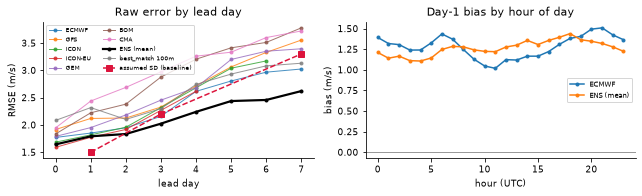

In [12]:
ASSUMED = {1: 1.5, 3: 2.2, 7: 3.3}
cmp_rows = []
for d, sd in ASSUMED.items():
    row = {"lead day": d, "assumed SD": sd, "assumed r": 0.95}
    for m in ["ecmwf_ifs025", "ENS", "best_match"]:
        s = ST[(ST["model"] == m) & (ST["d"] == d)].iloc[0]
        row[f"{LABEL[m]} SD"], row[f"{LABEL[m]} RMSE"], row[f"{LABEL[m]} bias"], row[f"{LABEL[m]} r"] = (
            s["SD"], s["RMSE"], s["bias"], s["r_lag1"])
    cmp_rows.append(row)
CMP = pd.DataFrame(cmp_rows).set_index("lead day")
display(CMP.round(2).T)

fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
for m in ORDER:
    s = ST[ST["model"] == m].sort_values("d")
    style = dict(lw=2.2, color="black") if m == "ENS" else dict(lw=1, alpha=0.8)
    ax[0].plot(s["d"], s["RMSE"], marker="o", ms=3, label=LABEL[m], **style)
ax[0].plot(list(ASSUMED), list(ASSUMED.values()), "s--", color="crimson", label="assumed SD (baseline)")
ax[0].set(xlabel="lead day", ylabel="RMSE (m/s)", title="Raw error by lead day")
ax[0].legend(fontsize=6, ncol=2)
for m in ["ecmwf_ifs025", "ENS"]:
    g = FCw[(FCw["model"] == m) & (FCw["d"] == 1)].groupby(FCw["time"].dt.hour)["e"].mean()
    ax[1].plot(g.index, g.values, marker="o", ms=3, label=LABEL[m])
ax[1].axhline(0, color="grey", lw=0.8)
ax[1].set(xlabel="hour (UTC)", ylabel="bias (m/s)", title="Day-1 bias by hour of day")
ax[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "error_by_lead.png", dpi=72)
plt.show()

## 4. Wind correction on a strict time split

- **Train:** 2024-03-13 to 2024-08-31. **Test:** 2024-09-01 to 2024-12-31 (4 months, never used for fitting, scaling
  or choosing anything).
- **Target:** the measured park wind at the full hour (section 2.2).
- **Methods**, each per lead day d:
  - (a) one raw model: ECMWF, and the single model with the lowest train RMSE at that lead day;
  - (a2) ECMWF with a linear correction a_d + b_d x forecast fitted on train;
  - (b) mean of the models (ENS), raw; (b2) ENS minus its train bias at that lead day;
  - (c) weights per lead day: non-negative weights for every model plus an intercept, least squares on train;
    a model missing on a row is replaced by the row's ENS. Distribution: (c) plus the 9 quantiles (P10 ... P90) of
    its train residuals at that lead day, the same for every hour;
  - (d) **MOS with CatBoost**, one model for all lead days, 9 quantiles (P10 ... P90) with `MultiQuantile` loss.
    Inputs: the seven model forecasts, their mean and spread, the lead day, the forecast direction (ECMWF, else GFS),
    solar hour and day of year. Quantile crossings are removed by sorting. Two forms:
    - **direct**: the quantiles of the measured wind;
    - **hybrid**: the quantiles of the residual of (c), added to (c). The linear part extrapolates; the trees add what
      depends on hour, direction, spread and lead day, and the interval.

    Each form with and without the day-of-year inputs (one year of data cannot teach season).
- **Choice of the CatBoost variant:** forward validation inside train (fit before June, validate June; before July,
  July; before August, August), by mean pinball loss over the 9 quantiles. Tree counts: early stopping on the
  validation month; the final count comes from the last fold (fit before August, validate August), then a refit on all
  of train.
- Disclosure: the direct form was run on test first; the hybrid form was added after seeing that the direct trees
  stopped at 55 and lost to (c). The choice between them below is made on validation only.

In [13]:
QS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
QCOLS = [f"q{int(a * 100)}" for a in QS]
ENS_COLS = [LABEL[m] for m in ENSEMBLE]

wide = FC[FC["model"].isin(ENSEMBLE)].pivot_table(index=["time", "d"], columns="model", values="ws").rename(columns=LABEL)
wd = FC[FC["model"].isin(["ecmwf_ifs025", "gfs_global"])].pivot_table(index=["time", "d"], columns="model", values="wd")
M = wide.reindex(columns=ENS_COLS).reset_index()
key = pd.MultiIndex.from_frame(M[["time", "d"]])
M["wd_fc"] = wd["ecmwf_ifs025"].fillna(wd["gfs_global"]).reindex(key).to_numpy()
M["best_match"] = FC[FC["model"] == "best_match"].set_index(["time", "d"])["ws"].reindex(key).to_numpy()
M = M[(M["time"] >= FC_START) & (M["time"] < TEST_END)].merge(P[["time", "ws_obs"]], on="time", how="left")
M["ens_mean"] = M[ENS_COLS].mean(axis=1)
M["ens_sd"] = M[ENS_COLS].std(axis=1)
M["n_models"] = M[ENS_COLS].notna().sum(axis=1)
M["wd_sin"], M["wd_cos"] = np.sin(np.radians(M["wd_fc"])), np.cos(np.radians(M["wd_fc"]))
solar = M["time"].dt.hour + LON / 15
M["hod_sin"], M["hod_cos"] = np.sin(2 * np.pi * solar / 24), np.cos(2 * np.pi * solar / 24)
doy = M["time"].dt.dayofyear
M["doy_sin"], M["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
M["split"] = np.where(M["time"] < TRAIN_END, "train", "test")
M = M[M["ens_mean"].notna()].reset_index(drop=True)
print(M.groupby(["split", "d"]).agg(rows=("time", "size"), with_truth=("ws_obs", "count")).unstack("d"))
TR = M[(M["split"] == "train") & M["ws_obs"].notna()]

       rows                                           with_truth                                          
d         0     1     2     3     4     5     6     7          0     1     2     3     4     5     6     7
split                                                                                                     
test   2928  2928  2928  2928  2928  2928  2928  2928       2919  2919  2919  2919  2919  2919  2919  2919
train  4128  4128  4128  4128  4128  4128  4128  4128       4108  4108  4108  4108  4108  4108  4108  4108


In [14]:
def fit_linear(x, y):
    A = np.c_[np.ones(len(x)), x]
    return np.linalg.lstsq(A, y, rcond=None)[0]


def ens_filled(df, cols):
    X = df[cols].to_numpy(float)
    fill = np.repeat(df["ens_mean"].to_numpy()[:, None], len(cols), axis=1)
    return np.where(np.isnan(X), fill, X)


def fit_simple(tr):
    """(a) best single, (a2), (b2), (c) and its residual quantiles, per lead day, fitted on `tr` only."""
    par = {}
    for d in LEADS:
        t = tr[tr["d"] == d]
        cols = [c for c in ENS_COLS if t[c].notna().mean() > 0.5]
        rmse = {c: np.sqrt(np.nanmean((t[c] - t["ws_obs"]) ** 2)) for c in cols}
        par[("best", d)] = min(rmse, key=rmse.get)
        ok = t["ECMWF"].notna()
        par[("lin", d)] = fit_linear(t.loc[ok, "ECMWF"].to_numpy(), t.loc[ok, "ws_obs"].to_numpy())
        par[("ens_bias", d)] = float((t["ens_mean"] - t["ws_obs"]).mean())
        X, y = ens_filled(t, cols), t["ws_obs"].to_numpy()
        w, _ = nnls(X - X.mean(0), y - y.mean())
        a = y.mean() - X.mean(0) @ w
        par[("w", d)] = (a, w, cols)
        par[("w_q", d)] = np.quantile(y - (a + X @ w), [0.1, 0.9])
        par[("w_qs", d)] = np.quantile(y - (a + X @ w), QS)
    return par


def simple_predictions(df, par):
    out = pd.DataFrame(index=df.index)
    best, lin, w_pred, lo, hi = (np.full(len(df), np.nan) for _ in range(5))
    for d in LEADS:
        m = (df["d"] == d).to_numpy()
        best[m] = df.loc[m, par[("best", d)]].to_numpy()
        lin[m] = par[("lin", d)][0] + par[("lin", d)][1] * df.loc[m, "ECMWF"].to_numpy()
        a, w, cols = par[("w", d)]
        w_pred[m] = a + ens_filled(df[m], cols) @ w
        lo[m], hi[m] = w_pred[m] + par[("w_q", d)][0], w_pred[m] + par[("w_q", d)][1]
    out["(a) raw ECMWF"], out["(a) raw best single"], out["(a2) ECMWF linear"] = df["ECMWF"], best, lin
    out["(b) ENS raw"] = df["ens_mean"]
    out["(b2) ENS - train bias"] = df["ens_mean"] - df["d"].map(lambda d: par[("ens_bias", d)])
    out["(c) weights per lead day"], out["(c) P10"], out["(c) P90"] = w_pred, lo, hi
    out["best_match 100m raw"] = df["best_match"]
    return out


SIMPLE = fit_simple(TR)
W = pd.DataFrame([{"d": d, "intercept": SIMPLE[("w", d)][0], **dict(zip(SIMPLE[("w", d)][2], SIMPLE[("w", d)][1])),
                   "sum of weights": SIMPLE[("w", d)][1].sum(), "best single (train)": SIMPLE[("best", d)]}
                  for d in LEADS]).set_index("d")
print("(c) weights per lead day, fitted on train:")
display(W.round(2))

(c) weights per lead day, fitted on train:


   intercept  ECMWF   GFS  ICON  ICON-EU   GEM   BOM   CMA  sum of weights best single (train)
d                                                                                             
0       0.62   0.20  0.07  0.00     0.15  0.11  0.21  0.00            0.74             ICON-EU
1       0.66   0.27  0.08  0.00     0.10  0.15  0.11  0.01            0.72             ICON-EU
2       0.80   0.27  0.16  0.02     0.10  0.08  0.08  0.01            0.71               ECMWF
3       0.82   0.28  0.15  0.00     0.07  0.11  0.06  0.03            0.71               ECMWF
4       1.09   0.15  0.13  0.00     0.15  0.13  0.06  0.04            0.67             ICON-EU
5       1.27   0.14  0.15  0.08      NaN  0.11  0.03  0.11            0.63               ECMWF
6       1.56   0.12  0.16  0.10      NaN  0.11  0.08  0.03            0.59               ECMWF
7       2.23   0.16  0.13   NaN      NaN  0.10  0.08  0.02            0.50               ECMWF

In [15]:
FEATS_ALL = ENS_COLS + ["ens_mean", "ens_sd", "n_models", "d", "wd_sin", "wd_cos", "hod_sin", "hod_cos", "doy_sin", "doy_cos"]
VARIANTS = {
    "direct, with season": ("direct", FEATS_ALL),
    "direct, without season": ("direct", [f for f in FEATS_ALL if not f.startswith("doy")]),
    "hybrid, with season": ("hybrid", FEATS_ALL + ["c_pred"]),
    "hybrid, without season": ("hybrid", [f for f in FEATS_ALL if not f.startswith("doy")] + ["c_pred"]),
}
MOS_PARAMS = dict(loss_function="MultiQuantile:alpha=" + ",".join(str(q) for q in QS), depth=6, learning_rate=0.05,
                  l2_leaf_reg=10, random_seed=SEED, verbose=0, thread_count=-1, allow_writing_files=False)


def mos_target(df, form):
    return df["ws_obs"] - df["c_pred"] if form == "hybrid" else df["ws_obs"]


def mos_fit(fit, variant, iterations=None, val=None):
    form, feats = VARIANTS[variant]
    m = CatBoostRegressor(**MOS_PARAMS, iterations=iterations or 3000)
    if val is not None:
        m.fit(fit[feats], mos_target(fit, form), eval_set=(val[feats], mos_target(val, form)), early_stopping_rounds=100)
        return m, max(50, m.get_best_iteration() + 1)
    m.fit(fit[feats], mos_target(fit, form))
    return m, iterations


def mos_quantiles(m, df, variant):
    form, feats = VARIANTS[variant]
    q = m.predict(df[feats]) + (df["c_pred"].to_numpy()[:, None] if form == "hybrid" else 0.0)
    return pd.DataFrame(np.sort(q, axis=1), index=df.index, columns=QCOLS)


def pinball(y, q, a):
    u = y - q
    return np.mean(np.maximum(a * u, (a - 1) * u))


def mean_pinball(y, Q):
    return np.mean([pinball(y, Q[c].to_numpy(), a) for c, a in zip(QCOLS, QS)])


# forward validation inside train; (c) is refitted in every fold, so c_pred is out of sample for the validation month
t0 = time.time()
fv = []
for vm in [6, 7, 8]:
    v0 = pd.Timestamp(f"2024-{vm:02d}-01")
    fit, val = TR[TR["time"] < v0].copy(), TR[(TR["time"] >= v0) & (TR["time"] < v0 + pd.offsets.MonthBegin(1))].copy()
    par = fit_simple(fit)
    fit["c_pred"] = simple_predictions(fit, par)["(c) weights per lead day"]
    val["c_pred"] = simple_predictions(val, par)["(c) weights per lead day"]
    y = val["ws_obs"].to_numpy()
    fv.append({"month": vm, "variant": "(c) weights per lead day", "trees": 0,
               "RMSE": np.sqrt(np.mean((val["c_pred"] - y) ** 2)), "pinball": np.nan})
    for v in VARIANTS:
        m, it = mos_fit(fit, v, val=val)
        Qv = mos_quantiles(m, val, v)
        fv.append({"month": vm, "variant": v, "trees": it, "RMSE": np.sqrt(np.mean((Qv["q50"] - y) ** 2)),
                   "pinball": mean_pinball(y, Qv)})
FV = pd.DataFrame(fv)
print(f"forward validation in {time.time() - t0:.0f} s")
display(FV.pivot(index="variant", columns="month", values=["RMSE", "pinball", "trees"]).round(3))
FV_MEAN = FV.groupby("variant")[["RMSE", "pinball"]].mean().sort_values("pinball")
display(FV_MEAN.round(3))
CHOSEN = FV_MEAN["pinball"].idxmin()
print("chosen CatBoost MOS variant (lowest validation pinball):", CHOSEN)

forward validation in 17 s


                           RMSE               pinball                trees              
month                         6      7      8       6      7      8      6      7      8
variant                                                                                 
(c) weights per lead day  1.377  1.466  1.422     NaN    NaN    NaN    0.0    0.0    0.0
direct, with season       1.449  1.398  1.550   0.445  0.409  0.442   50.0  130.0   55.0
direct, without season    1.350  1.453  1.418   0.405  0.421  0.403  317.0   83.0  131.0
hybrid, with season       1.378  1.375  1.428   0.418  0.403  0.415   50.0  141.0   50.0
hybrid, without season    1.360  1.445  1.412   0.408  0.418  0.401  231.0  114.0   90.0

                           RMSE  pinball
variant                                 
hybrid, without season    1.406    0.409
direct, without season    1.407    0.410
hybrid, with season       1.393    0.412
direct, with season       1.466    0.432
(c) weights per lead day  1.422      NaN

chosen CatBoost MOS variant (lowest validation pinball): hybrid, without season


In [16]:
# final fits: tree count from the last fold (fit before August, validate August), refit on all of train
par_aug = fit_simple(TR[TR["time"] < VAL_START])
TRc = TR.copy()
TRc["c_pred"] = simple_predictions(TRc, SIMPLE)["(c) weights per lead day"]
fit_aug = TR[TR["time"] < VAL_START].copy()
val_aug = TR[TR["time"] >= VAL_START].copy()
fit_aug["c_pred"] = simple_predictions(fit_aug, par_aug)["(c) weights per lead day"]
val_aug["c_pred"] = simple_predictions(val_aug, par_aug)["(c) weights per lead day"]
MOS = {}
for v in VARIANTS:
    _, it = mos_fit(fit_aug, v, val=val_aug)
    MOS[v], _ = mos_fit(TRc, v, iterations=it)
    print(f"{v}: {it} trees")

M["c_pred"] = simple_predictions(M, SIMPLE)["(c) weights per lead day"]
PRED = simple_predictions(M, SIMPLE)


def c_quantiles(c_pred, d, par):
    """(c) plus its 9 train residual quantiles of that lead day: the full distribution of the simple method."""
    res = np.stack([par[("w_qs", x)] for x in d])
    return pd.DataFrame(np.asarray(c_pred, float)[:, None] + res, index=c_pred.index, columns=QCOLS)


Q_C = c_quantiles(M["c_pred"], M["d"].to_numpy(), SIMPLE)
QV = {v: mos_quantiles(MOS[v], M, v) for v in VARIANTS}
for v in VARIANTS:
    PRED[f"(d) MOS {v} P50"] = QV[v]["q50"]
Q_ALL = QV[CHOSEN]
PRED["(d) P10"], PRED["(d) P90"] = Q_ALL["q10"], Q_ALL["q90"]
POINT = ["(a) raw ECMWF", "(a) raw best single", "(a2) ECMWF linear", "(b) ENS raw", "(b2) ENS - train bias",
         "(c) weights per lead day"] + [f"(d) MOS {v} P50" for v in VARIANTS] + ["best_match 100m raw"]

# out-of-fold MOS on the train period (monthly folds; (c) refitted per fold too), used only for the blend in section 6
TR_ALL = M[M["split"] == "train"].copy()
fold = TR_ALL["time"].dt.month.to_numpy()
OOF = pd.DataFrame(index=TR_ALL.index, columns=QCOLS, dtype=float)
OOF_C = pd.DataFrame(index=TR_ALL.index, columns=QCOLS, dtype=float)
OOF_CPRED = pd.Series(np.nan, index=TR_ALL.index)
for mo in np.unique(fold):
    fit = TR_ALL[(fold != mo) & TR_ALL["ws_obs"].notna().to_numpy()].copy()
    par = fit_simple(fit)
    fit["c_pred"] = simple_predictions(fit, par)["(c) weights per lead day"]
    hold = TR_ALL[fold == mo].copy()
    hold["c_pred"] = simple_predictions(hold, par)["(c) weights per lead day"]
    OOF_C.loc[fold == mo] = c_quantiles(hold["c_pred"], hold["d"].to_numpy(), par).to_numpy()
    OOF_CPRED.loc[fold == mo] = hold["c_pred"].to_numpy()
    m_k, _ = mos_fit(fit, CHOSEN, iterations=MOS[CHOSEN].tree_count_)
    OOF.loc[fold == mo] = mos_quantiles(m_k, hold, CHOSEN).to_numpy()
print(f"all MOS fits done in {time.time() - t0:.0f} s")

# interval calibration per lead day, from the out-of-fold train predictions only: every quantile is moved away from
# P50 by a factor k_d chosen so that 80% of the train hours fall inside P10-P90
def widen(Q, k):
    return Q.sub(Q["q50"], axis=0).mul(k, axis=0).add(Q["q50"], axis=0)


KCAL = {}
y_oof = TR_ALL["ws_obs"].to_numpy()
for d in LEADS:
    m = (TR_ALL["d"] == d).to_numpy() & ~np.isnan(y_oof)
    Qd = OOF[m]
    cover = {k: np.mean((y_oof[m] >= widen(Qd, k)["q10"]) & (y_oof[m] <= widen(Qd, k)["q90"])) for k in np.arange(0.8, 2.001, 0.01)}
    KCAL[d] = min(cover, key=lambda k: abs(cover[k] - 0.80))
print("interval factor per lead day (from out-of-fold train):", {d: round(k, 2) for d, k in KCAL.items()})
Q_CAL = widen(Q_ALL, M["d"].map(KCAL))
PRED["(d) P10 calibrated"], PRED["(d) P90 calibrated"] = Q_CAL["q10"], Q_CAL["q90"]

direct, with season: 55 trees


direct, without season: 131 trees


hybrid, with season: 50 trees


hybrid, without season: 90 trees


all MOS fits done in 26 s


interval factor per lead day (from out-of-fold train): {0: np.float64(0.96), 1: np.float64(1.03), 2: np.float64(1.06), 3: np.float64(1.05), 4: np.float64(1.09), 5: np.float64(1.02), 6: np.float64(1.11), 7: np.float64(1.15)}


### 4.1 Test results (September-December 2024)

In [17]:
te = M.index[(M["split"] == "test") & M["ws_obs"].notna()]
rows = []
for d in LEADS:
    idx = te[M.loc[te, "d"] == d]
    y = M.loc[idx, "ws_obs"].to_numpy()
    for name in POINT:
        p = PRED.loc[idx, name].to_numpy(float)
        ok = ~np.isnan(p)
        e = p[ok] - y[ok]
        rows.append({"d": d, "method": name, "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)), "bias": e.mean(),
                     "n": int(ok.sum())})
WIND_TEST = pd.DataFrame(rows)
for stat in ["RMSE", "MAE", "bias"]:
    print(f"TEST, {stat} (m/s) by lead day:")
    display(WIND_TEST.pivot(index="method", columns="d", values=stat).reindex(POINT).round(2))
ref = WIND_TEST[WIND_TEST["method"] == "(a) raw ECMWF"].set_index("d")["RMSE"]
GAIN = WIND_TEST.pivot(index="method", columns="d", values="RMSE").reindex(POINT).div(ref, axis=1).rsub(1)
print("TEST, RMSE reduction against raw ECMWF (fraction):")
display(GAIN.round(3))
WIND_TEST.to_csv(OUT / "wind_correction_test.csv", index=False)

TEST, RMSE (m/s) by lead day:


d                                      0     1     2     3     4     5     6     7
method                                                                            
(a) raw ECMWF                       1.79  1.88  2.00  2.25  2.68  2.84  3.00  2.99
(a) raw best single                 1.60  1.80  2.00  2.25  2.84  2.84  3.00  2.99
(a2) ECMWF linear                   1.06  1.18  1.38  1.63  2.10  2.17  2.36  2.46
(b) ENS raw                         1.67  1.81  1.84  2.09  2.33  2.49  2.49  2.65
(b2) ENS - train bias               1.15  1.28  1.37  1.64  1.93  2.07  2.13  2.34
(c) weights per lead day            0.85  0.99  1.16  1.40  1.75  1.93  2.06  2.27
(d) MOS direct, with season P50     1.18  1.28  1.38  1.61  1.85  2.05  2.15  2.35
(d) MOS direct, without season P50  0.94  1.07  1.20  1.47  1.77  1.96  2.07  2.29
(d) MOS hybrid, with season P50     0.86  1.01  1.17  1.45  1.83  2.07  2.20  2.40
(d) MOS hybrid, without season P50  0.84  1.00  1.16  1.41  1.77  1.94  2.06  2.27
best

TEST, MAE (m/s) by lead day:


d                                      0     1     2     3     4     5     6     7
method                                                                            
(a) raw ECMWF                       1.46  1.54  1.62  1.80  2.08  2.21  2.34  2.37
(a) raw best single                 1.28  1.41  1.62  1.80  2.11  2.21  2.34  2.37
(a2) ECMWF linear                   0.79  0.90  1.05  1.22  1.55  1.65  1.80  1.89
(b) ENS raw                         1.34  1.46  1.46  1.62  1.81  1.93  1.97  2.07
(b2) ENS - train bias               0.89  0.99  1.06  1.23  1.43  1.56  1.66  1.85
(c) weights per lead day            0.65  0.78  0.90  1.07  1.27  1.42  1.57  1.75
(d) MOS direct, with season P50     0.84  0.95  1.03  1.22  1.37  1.55  1.67  1.83
(d) MOS direct, without season P50  0.69  0.82  0.92  1.11  1.30  1.47  1.59  1.78
(d) MOS hybrid, with season P50     0.67  0.80  0.92  1.14  1.36  1.59  1.75  1.91
(d) MOS hybrid, without season P50  0.64  0.79  0.90  1.08  1.29  1.44  1.58  1.77
best

TEST, bias (m/s) by lead day:


d                                      0     1     2     3     4     5     6     7
method                                                                            
(a) raw ECMWF                       1.29  1.34  1.34  1.30  1.21  1.30  1.20  1.06
(a) raw best single                 0.96  0.97  1.34  1.30  1.07  1.30  1.20  1.06
(a2) ECMWF linear                  -0.08 -0.05 -0.02 -0.04 -0.18 -0.19 -0.23 -0.25
(b) ENS raw                         1.21  1.28  1.23  1.30  1.31  1.40  1.29  1.23
(b2) ENS - train bias               0.05  0.03  0.03  0.08  0.07  0.02  0.05 -0.00
(c) weights per lead day           -0.04 -0.06 -0.06 -0.03 -0.08 -0.10 -0.13 -0.18
(d) MOS direct, with season P50    -0.00  0.04  0.01  0.08  0.07  0.14  0.11 -0.02
(d) MOS direct, without season P50 -0.14 -0.10 -0.12 -0.07 -0.06 -0.10 -0.14 -0.31
(d) MOS hybrid, with season P50     0.12  0.11  0.12  0.33  0.38  0.58  0.56  0.51
(d) MOS hybrid, without season P50 -0.05 -0.06 -0.07 -0.02 -0.06 -0.10 -0.15 -0.22
best

TEST, RMSE reduction against raw ECMWF (fraction):


d                                       0      1      2      3      4      5      6      7
method                                                                                    
(a) raw ECMWF                       0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
(a) raw best single                 0.108  0.038  0.000  0.000 -0.060  0.000  0.000  0.000
(a2) ECMWF linear                   0.408  0.372  0.312  0.276  0.214  0.235  0.214  0.179
(b) ENS raw                         0.070  0.037  0.081  0.072  0.128  0.123  0.170  0.115
(b2) ENS - train bias               0.357  0.320  0.318  0.272  0.278  0.273  0.290  0.216
(c) weights per lead day            0.524  0.471  0.419  0.379  0.347  0.323  0.314  0.243
(d) MOS direct, with season P50     0.343  0.319  0.311  0.286  0.307  0.277  0.283  0.213
(d) MOS direct, without season P50  0.476  0.430  0.399  0.348  0.338  0.309  0.311  0.236
(d) MOS hybrid, with season P50     0.518  0.462  0.415  0.354  0.317  0.272  0.266  0.197

### 4.2 Is the gain real? Paired block bootstrap over test days

Difference of RMSE (m/s) between two methods, 1000 resamples of the 122 test days (the hours of one day share the
weather, so a day is the unit). Negative = the first method errs less.

In [18]:
def boot_rmse_diff(a, b, d, n_boot=1000, seed=7):
    idx = te[M.loc[te, "d"] == d]
    y = M.loc[idx, "ws_obs"].to_numpy()
    pa, pb = PRED.loc[idx, a].to_numpy(float), PRED.loc[idx, b].to_numpy(float)
    ok = ~np.isnan(pa) & ~np.isnan(pb)
    day = M.loc[idx, "time"].dt.floor("D").to_numpy()[ok]
    A = pd.DataFrame({"day": day, "a": (pa[ok] - y[ok]) ** 2, "b": (pb[ok] - y[ok]) ** 2, "n": 1.0}).groupby("day").sum().to_numpy()
    S = A[np.random.default_rng(seed).integers(0, len(A), size=(n_boot, len(A)))].sum(1)
    diff = np.sqrt(S[:, 0] / S[:, 2]) - np.sqrt(S[:, 1] / S[:, 2])
    point = np.sqrt(A[:, 0].sum() / A[:, 2].sum()) - np.sqrt(A[:, 1].sum() / A[:, 2].sum())
    return point, *np.percentile(diff, [2.5, 97.5])


BEST_D = f"(d) MOS {CHOSEN} P50"
brows = []
for d in LEADS:
    for a, b in [(BEST_D, "(a) raw ECMWF"), (BEST_D, "best_match 100m raw"), (BEST_D, "(c) weights per lead day"),
                 ("(c) weights per lead day", "(b2) ENS - train bias"), ("(b2) ENS - train bias", "(a2) ECMWF linear")]:
        p, lo, hi = boot_rmse_diff(a, b, d)
        brows.append({"d": d, "comparison": f"{a} - {b}", "RMSE diff [95% CI]": f"{p:+.2f} [{lo:+.2f}, {hi:+.2f}]"})
BOOT_WIND = pd.DataFrame(brows).pivot(index="comparison", columns="d", values="RMSE diff [95% CI]")
display(BOOT_WIND)

d                                                                                 0                     1                     2                     3                     4                     5                     6  \
comparison                                                                                                                                                                                                                
(b2) ENS - train bias - (a2) ECMWF linear                      +0.09 [-0.01, +0.20]  +0.10 [-0.00, +0.20]  -0.01 [-0.13, +0.10]  +0.01 [-0.18, +0.22]  -0.17 [-0.42, +0.10]  -0.11 [-0.31, +0.10]  -0.23 [-0.45, +0.01]   
(c) weights per lead day - (b2) ENS - train bias               -0.30 [-0.38, -0.23]  -0.28 [-0.36, -0.22]  -0.20 [-0.29, -0.12]  -0.24 [-0.38, -0.12]  -0.19 [-0.35, -0.03]  -0.14 [-0.27, -0.03]  -0.07 [-0.21, +0.06]   
(d) MOS hybrid, without season P50 - (a) raw ECMWF             -0.95 [-1.07, -0.84]  -0.88 [-1.00, -0.77]  -0.84 [-0.96, -0.

### 4.3 Uncertainty: coverage of the P10-P90 interval on test (nominal 0.80)

In [19]:
crow = []
for d in LEADS:
    idx = te[M.loc[te, "d"] == d]
    y = M.loc[idx, "ws_obs"].to_numpy()
    for name, L, H_ in [("(c) residual quantiles", PRED.loc[idx, "(c) P10"], PRED.loc[idx, "(c) P90"])] + [
            (f"(d) {v}", QV[v].loc[idx, "q10"], QV[v].loc[idx, "q90"]) for v in VARIANTS] + [
            (f"(d) {CHOSEN}, calibrated", Q_CAL.loc[idx, "q10"], Q_CAL.loc[idx, "q90"])]:
        L, H_ = L.to_numpy(float), H_.to_numpy(float)
        r = {"d": d, "method": name, "coverage": np.mean((y >= L) & (y <= H_)), "width m/s": np.mean(H_ - L),
             "below P10": np.mean(y < L), "above P90": np.mean(y > H_)}
        if name.startswith("(d)"):
            r["pinball"] = mean_pinball(y, (Q_CAL if name.endswith("calibrated") else QV[name[4:]]).loc[idx])
        else:   # (c) with its 9 train residual quantiles, the same for every hour of a lead day
            qc = PRED.loc[idx, "(c) weights per lead day"].to_numpy()[:, None] + SIMPLE[("w_qs", d)][None, :]
            r["pinball"] = mean_pinball(y, pd.DataFrame(qc, columns=QCOLS))
        crow.append(r)
COV = pd.DataFrame(crow)
for stat in ["coverage", "width m/s", "pinball"]:
    print(f"TEST, {stat} by lead day:")
    display(COV.pivot(index="method", columns="d", values=stat).round(3))
COV.to_csv(OUT / "interval_coverage_test.csv", index=False)
fi = pd.Series(MOS[CHOSEN].get_feature_importance(), index=VARIANTS[CHOSEN][1]).sort_values(ascending=False)
print(f"feature importance, {CHOSEN}:", fi.round(1).to_dict())

TEST, coverage by lead day:


d                                           0      1      2      3      4      5      6      7
method                                                                                        
(c) residual quantiles                  0.774  0.763  0.760  0.781  0.789  0.786  0.784  0.779
(d) direct, with season                 0.804  0.749  0.727  0.706  0.727  0.756  0.734  0.702
(d) direct, without season              0.767  0.709  0.711  0.717  0.734  0.774  0.752  0.741
(d) hybrid, with season                 0.772  0.717  0.685  0.640  0.652  0.645  0.601  0.577
(d) hybrid, without season              0.782  0.735  0.726  0.748  0.748  0.777  0.751  0.727
(d) hybrid, without season, calibrated  0.762  0.748  0.756  0.769  0.778  0.785  0.798  0.798

TEST, width m/s by lead day:


d                                           0      1      2      3      4      5      6      7
method                                                                                        
(c) residual quantiles                  1.948  2.271  2.615  3.172  3.828  4.276  4.849  5.152
(d) direct, with season                 2.571  2.630  2.757  3.111  3.616  4.569  4.662  4.765
(d) direct, without season              2.015  2.162  2.457  2.911  3.499  4.455  4.587  4.815
(d) hybrid, with season                 2.036  2.144  2.320  2.642  3.077  3.593  3.740  3.804
(d) hybrid, without season              1.968  2.194  2.487  3.024  3.542  4.318  4.522  4.726
(d) hybrid, without season, calibrated  1.889  2.259  2.636  3.175  3.861  4.405  5.020  5.435

TEST, pinball by lead day:


d                                           0      1      2      3      4      5      6      7
method                                                                                        
(c) residual quantiles                  0.257  0.303  0.354  0.420  0.507  0.566  0.619  0.685
(d) direct, with season                 0.328  0.368  0.404  0.476  0.542  0.613  0.653  0.716
(d) direct, without season              0.275  0.322  0.365  0.438  0.516  0.581  0.625  0.691
(d) hybrid, with season                 0.263  0.311  0.361  0.450  0.547  0.635  0.695  0.765
(d) hybrid, without season              0.253  0.305  0.353  0.420  0.511  0.570  0.621  0.690
(d) hybrid, without season, calibrated  0.253  0.305  0.352  0.419  0.510  0.570  0.619  0.686

feature importance, hybrid, without season: {'wd_sin': 13.1, 'd': 9.9, 'wd_cos': 9.3, 'ens_sd': 9.1, 'hod_cos': 8.5, 'c_pred': 7.7, 'CMA': 7.3, 'hod_sin': 7.2, 'n_models': 6.2, 'ECMWF': 4.6, 'GFS': 4.4, 'GEM': 3.7, 'ens_mean': 2.7, 'ICON-EU': 2.6, 'ICON': 2.3, 'BOM': 1.4}


## 5. Power: real forecast error through the ML2 wind-to-power model

- **Wind-to-power model, as in ML2 and not tuned:** CatBoost with the ML2 parameters (depth 6, at most 600 trees,
  learning rate 0.05, L2 10, RMSE) and the generic 15-minute features (`ws`, `ws_d1`, `ws_sd3`, solar hour, day of
  year, quarter). Trained on Kelmarsh **measured** wind, every turbine, 2016-01 to 2024-08 (before the test months),
  at most 500,000 random quarters. Tree count by early stopping on the last 12 months before test (fit on earlier
  data), then a refit.
- **Serving recipe of the ML2 contract:** the hourly forecast is instantaneous at the full hour; each quarter takes the
  linear interpolation at its centre. One park forecast feeds all six turbines.
- **Test:** every clean quarter of the six turbines, 2024-09-01 to 2024-12-31.
- **Rows, as in the ML2 baseline:** measured wind; lead day d (every hour forecast d days before); and the **whole
  week**: inside each calendar week (weeks counted from 1970-01-01, as in the baseline), day k of the week uses the
  lead-day-k forecast, k = 1..7.
- **Metrics:** R2 per quarter; WAPE of the energy per turbine and day (days with >= 72 clean quarters) at each lead day;
  WAPE of the weekly energy for the whole week (weeks with >= 480 clean quarters, as in the baseline).

In [20]:
PCB = dict(loss_function="RMSE", depth=6, learning_rate=0.05, l2_leaf_reg=10, random_seed=SEED, verbose=0,
           thread_count=-1, allow_writing_files=False)
F15 = ["ws", "ws_d1", "ws_sd3", "hod_sin", "hod_cos", "doy_sin", "doy_cos", "quarter"]


def quarters_measured_from(qt, hn):
    q = qt.copy()
    q["hour"], q["k"] = q["qs"].dt.floor("h"), (q["qs"].dt.minute // 15).to_numpy()
    q = q.merge(hn[["turbine", "hour", "ws", "ws_prev", "ws_next", "ws_d1", "ws_sd3"]], on=["turbine", "hour"], how="left")
    d = QUARTER_OFFSET[q["k"].to_numpy()]
    nb = np.where(d < 0, q["ws_prev"], q["ws_next"])
    nb = np.where(np.isnan(nb), q["ws"], nb)
    q["ws"] = q["ws"] + np.abs(d) * (nb - q["ws"])
    for c, v in time_features(q["qs"], q["k"].to_numpy()).items():
        q[c] = v
    return q


t0 = time.time()
rng = np.random.default_rng(SEED)
QM = quarters_measured_from(QT[QT["qs"] < TRAIN_END], HN)
QM = QM[QM["cf15"].notna() & QM["ws"].notna()]
fit_i = np.flatnonzero((QM["qs"] < TRAIN_END - pd.DateOffset(years=1)).to_numpy())
val_i = np.flatnonzero((QM["qs"] >= TRAIN_END - pd.DateOffset(years=1)).to_numpy())
fit_i = np.sort(rng.choice(fit_i, min(500_000, len(fit_i)), replace=False))
val_i = np.sort(rng.choice(val_i, min(250_000, len(val_i)), replace=False))
pm = CatBoostRegressor(**PCB, iterations=600)
pm.fit(QM.iloc[fit_i][F15], QM.iloc[fit_i]["cf15"], eval_set=(QM.iloc[val_i][F15], QM.iloc[val_i]["cf15"]),
       early_stopping_rounds=50)
P_TREES = max(50, pm.get_best_iteration() + 1)
all_i = np.sort(rng.choice(len(QM), min(500_000, len(QM)), replace=False))
POWER = CatBoostRegressor(**PCB, iterations=P_TREES)
POWER.fit(QM.iloc[all_i][F15], QM.iloc[all_i]["cf15"])
print(f"power model: {P_TREES} trees, {len(QM):,} training quarters available, {time.time() - t0:.0f} s")


def power_cf(X):
    """cf per row, clipped to [0, 1]; NaN where the wind input is missing."""
    p = np.clip(POWER.predict(X[F15]), 0, 1)
    return np.where(np.isnan(X["ws"].to_numpy(float)), np.nan, p)

power model: 333 trees, 1,731,441 training quarters available, 6 s


In [21]:
QTE = quarters_measured_from(QT[(QT["qs"] >= TRAIN_END) & (QT["qs"] < TEST_END)], HN)
QTE = QTE[QTE["cf15"].notna()].reset_index(drop=True)
QTE["day"] = QTE["qs"].dt.floor("D")
QTE["epoch_day"] = (QTE["day"] - pd.Timestamp("1970-01-01")).dt.days
QTE["week"] = QTE["epoch_day"] // 7
QTE["week_lead"] = QTE["epoch_day"] % 7 + 1
QG = pd.DataFrame({"qs": pd.date_range(TRAIN_END, TEST_END - pd.Timedelta(minutes=15), freq="15min")})
qpos = pd.Index(QG["qs"]).get_indexer(QTE["qs"])
Y = QTE["cf15"].to_numpy()
print(f"test quarters with a clean target: {len(QTE):,} ({QTE['turbine'].nunique()} turbines)")


def grid_power(series):
    """Park power (cf) on the test quarter grid from an hourly wind series indexed by the full hour."""
    return power_cf(quarters_from_hourly(series.dropna(), QG["qs"]))


def lead_series(values, d):
    sel = (M["d"] == d).to_numpy()
    return pd.Series(np.asarray(values, float)[sel], index=M.loc[sel, "time"])


SCEN = {   # name -> hourly wind values aligned with M (one per (time, d))
    "raw ECMWF 80 m": PRED["(a) raw ECMWF"],
    "app today: best_match 100 m raw": PRED["best_match 100m raw"],
    "(b) ENS raw": PRED["(b) ENS raw"],
    "(c) weights per lead day": PRED["(c) weights per lead day"],
    "(d) MOS hybrid P50": Q_CAL["q50"],
}
PP = {}   # (scenario, d) -> cf per test row (QTE order)
for name, vals in SCEN.items():
    for d in LEADS:
        PP[(name, d)] = grid_power(lead_series(vals, d))[qpos]
# expected power: mean of the power of the 9 quantile series, for (c) with its residual quantiles and for the MOS
for tag, QQ in [("(c)", Q_C), ("(d) MOS", Q_CAL)]:
    for d in LEADS:
        PP[(f"{tag} expected power", d)] = np.mean([grid_power(lead_series(QQ[c], d))[qpos] for c in QCOLS], axis=0)
        PP[(f"{tag} power P10", d)] = grid_power(lead_series(QQ["q10"], d))[qpos]
        PP[(f"{tag} power P90", d)] = grid_power(lead_series(QQ["q90"], d))[qpos]
MEAS = power_cf(QTE)
print(f"scenario predictions in {time.time() - t0:.0f} s")

test quarters with a clean target: 67,781 (6 turbines)


scenario predictions in 7 s


The assumed error of the baseline, applied to Kelmarsh: the same simulation as `care_ml2_power_15min` (shared by the
park, AR(1) r = 0.95, SD 1.5 / 2.2 / 3.3 m/s, ramp inside each week, seeds 500-502), added to the measured hourly wind
of each turbine in the test months. It puts the assumed and the real error on the same turbines and quarters.

In [22]:
NOISE_SD = {1: 1.5, 3: 2.2, 7: 3.3}
hours = pd.date_range(TRAIN_END - pd.Timedelta(hours=2), TEST_END, freq="h")
HN_TE = HN[(HN["hour"] >= hours[0]) & (HN["hour"] <= hours[-1])][["turbine", "hour", "ws"]].copy()


def noisy_power(case, seed):
    z = np.random.default_rng(seed).standard_normal(len(hours))
    e = np.empty(len(hours))
    e[0] = z[0]
    for i in range(1, len(hours)):
        e[i] = 0.95 * e[i - 1] + np.sqrt(1 - 0.95 ** 2) * z[i]
    if case == "ramp":
        lead = (hours.values.astype("datetime64[h]").astype(np.int64) / 24.0) % 7 + 1 / 24
        sd = np.interp(lead, [1, 3, 7], [NOISE_SD[1], NOISE_SD[3], NOISE_SD[7]])
    else:
        sd = NOISE_SD[case]
    hn = HN_TE.merge(pd.DataFrame({"hour": hours, "e": e * sd}), on="hour", how="left")
    hn["ws"] = np.maximum(hn["ws"] + hn["e"], 0.0)
    hn = add_wind_features(hn.sort_values(["turbine", "hour"]).reset_index(drop=True), "turbine")
    return power_cf(quarters_measured_from(QTE[["turbine", "qs", "cf15"]], hn))


ASSUMED_P = {case: [noisy_power(case, 500 + k) for k in range(3)] for case in [1, 3, 7, "ramp"]}
print(f"assumed-error draws in {time.time() - t0:.0f} s")

assumed-error draws in 7 s


In [23]:
def r2(y, p):
    ok = ~np.isnan(p)
    return 1 - np.sum((p[ok] - y[ok]) ** 2) / np.sum((y[ok] - y[ok].mean()) ** 2)


def wape(p, level, min_q):
    g = pd.DataFrame({"t": QTE["turbine"], "u": QTE[level], "y": Y, "p": p}).dropna()
    s = g.groupby(["t", "u"]).agg(n=("y", "size"), E=("y", "sum"), P=("p", "sum"))
    s = s[s["n"] >= min_q]
    return float((s["P"] - s["E"]).abs().sum() / s["E"].sum()), float((s["P"] - s["E"]).sum() / s["E"].sum())


def week_composite(name):
    p = np.full(len(QTE), np.nan)
    for k in range(1, 8):
        m = (QTE["week_lead"] == k).to_numpy()
        p[m] = PP[(name, k)][m]
    return p


PNAMES = list(SCEN) + ["(c) expected power", "(d) MOS expected power"]
for name in PNAMES:
    PP[(name, "week")] = week_composite(name)
rows = []
for name in PNAMES:
    for d in LEADS + ["week"]:
        p = PP[(name, d)]
        w_day, b_day = wape(p, "day", 72)
        w_wk, b_wk = wape(p, "week", 480) if d == "week" else (np.nan, np.nan)
        rows.append({"scenario": name, "d": d, "R2 15 min": r2(Y, p), "WAPE day": w_day, "bias day": b_day,
                     "WAPE week": w_wk, "bias week": b_wk})
for case, draws in ASSUMED_P.items():
    d = "week" if case == "ramp" else case
    rows.append({"scenario": "assumed error (baseline simulation)", "d": d, "R2 15 min": np.mean([r2(Y, p) for p in draws]),
                 "WAPE day": np.mean([wape(p, "day", 72)[0] for p in draws]), "bias day": np.nan,
                 "WAPE week": np.mean([wape(p, "week", 480)[0] for p in draws]) if d == "week" else np.nan, "bias week": np.nan})
w_d, b_d = wape(MEAS, "day", 72)
w_w, b_w = wape(MEAS, "week", 480)
rows.append({"scenario": "measured wind", "d": "measured", "R2 15 min": r2(Y, MEAS), "WAPE day": w_d, "bias day": b_d,
             "WAPE week": w_w, "bias week": b_w})
POWER_RES = pd.DataFrame(rows)
POWER_RES.to_csv(OUT / "power_by_lead_test.csv", index=False)
COLS_ORDER = ["measured", 0, 1, 2, 3, 4, 5, 6, 7, "week"]
SC_ORDER = ["measured wind", "assumed error (baseline simulation)"] + PNAMES
for stat in ["R2 15 min", "WAPE day", "bias day"]:
    print(f"TEST, {stat}: rows = scenario, columns = lead day ('week' = whole week, day k uses lead day k)")
    t = POWER_RES.pivot_table(index="scenario", columns="d", values=stat, aggfunc="first")
    display(t.reindex(index=SC_ORDER, columns=[c for c in COLS_ORDER if c in t.columns]).round(3))
print("TEST, whole week: WAPE and bias of the weekly energy")
display(POWER_RES[POWER_RES["d"].isin(["week", "measured"])].set_index("scenario")[["R2 15 min", "WAPE week", "bias week"]]
        .reindex(SC_ORDER).round(3))

TEST, R2 15 min: rows = scenario, columns = lead day ('week' = whole week, day k uses lead day k)


d                                    measured      0      1      2      3      4      5      6      7   week
scenario                                                                                                    
measured wind                           0.972    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
assumed error (baseline simulation)       NaN    NaN  0.740    NaN  0.510    NaN    NaN    NaN  0.108  0.464
raw ECMWF 80 m                            NaN  0.500  0.479  0.418  0.274  0.064 -0.094 -0.143 -0.085  0.198
app today: best_match 100 m raw           NaN  0.272  0.092  0.329  0.189 -0.020 -0.188 -0.225 -0.160  0.089
(b) ENS raw                               NaN  0.606  0.549  0.524  0.426  0.291  0.168  0.131  0.013  0.326
(c) weights per lead day                  NaN  0.827  0.795  0.755  0.676  0.586  0.471  0.432  0.304  0.574
(d) MOS hybrid P50                        NaN  0.823  0.787  0.746  0.659  0.566  0.444  0.413  0.270  0.553
(c) expected power 

TEST, WAPE day: rows = scenario, columns = lead day ('week' = whole week, day k uses lead day k)


d                                    measured      0      1      2      3      4      5      6      7   week
scenario                                                                                                    
measured wind                           0.029    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
assumed error (baseline simulation)       NaN    NaN  0.284    NaN  0.401    NaN    NaN    NaN  0.556  0.414
raw ECMWF 80 m                            NaN  0.457  0.462  0.467  0.504  0.569  0.600  0.593  0.569  0.519
app today: best_match 100 m raw           NaN  0.616  0.673  0.529  0.559  0.617  0.647  0.629  0.606  0.579
(b) ENS raw                               NaN  0.396  0.414  0.408  0.439  0.486  0.534  0.561  0.575  0.476
(c) weights per lead day                  NaN  0.163  0.185  0.206  0.252  0.312  0.361  0.396  0.479  0.322
(d) MOS hybrid P50                        NaN  0.164  0.193  0.212  0.260  0.321  0.373  0.396  0.480  0.329
(c) expected power 

TEST, bias day: rows = scenario, columns = lead day ('week' = whole week, day k uses lead day k)


d                                    measured      0      1      2      3      4      5      6      7   week
scenario                                                                                                    
measured wind                           -0.01    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
assumed error (baseline simulation)       NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
raw ECMWF 80 m                            NaN  0.453  0.456  0.455  0.443  0.434  0.485  0.431  0.346  0.382
app today: best_match 100 m raw           NaN  0.616  0.671  0.522  0.509  0.499  0.550  0.495  0.412  0.460
(b) ENS raw                               NaN  0.389  0.403  0.390  0.397  0.412  0.447  0.425  0.397  0.373
(c) weights per lead day                  NaN -0.062 -0.078 -0.092 -0.083 -0.113 -0.138 -0.171 -0.243 -0.155
(d) MOS hybrid P50                        NaN -0.074 -0.087 -0.107 -0.093 -0.117 -0.147 -0.179 -0.249 -0.168
(c) expected power 

TEST, whole week: WAPE and bias of the weekly energy


                                     R2 15 min  WAPE week  bias week
scenario                                                            
measured wind                            0.972      0.019     -0.010
assumed error (baseline simulation)      0.464      0.253        NaN
raw ECMWF 80 m                           0.198      0.410      0.384
app today: best_match 100 m raw          0.089      0.477      0.462
(b) ENS raw                              0.326      0.381      0.373
(c) weights per lead day                 0.574      0.214     -0.155
(d) MOS hybrid P50                       0.553      0.223     -0.167
(c) expected power                       0.592      0.197     -0.105
(d) MOS expected power                   0.577      0.204     -0.118

### 5.1 From Kelmarsh to CARE: an error generator checked against the real forecast

CARE locations are anonymised, so the real forecast cannot be fetched there; the real error has to be carried over by
simulation. Before doing that (`care_ml2_real_error.ipynb`), the simulation is checked here, on the test months, against
the real forecast it is meant to imitate. Two forms:
- **baseline form** (as in `care_ml2_power_15min`): each turbine keeps its own measured wind, plus an error shared by
  the park, AR(1), with the bias, SD and hour-to-hour r of the real error;
- **park form**: every turbine gets one park wind, as at serving: forecast = m + bias + beta x (park wind - m) + u, with
  m the park's mean wind, u AR(1). beta < 1 is the shrinkage of a corrected forecast towards the mean; raw forecasts
  have beta near 1 at short leads.

The parameters are fitted per lead day on the real error of the test months (the check is about the form, not the
fit).

In [24]:
ERR = M[["time", "d", "split", "ws_obs"]].copy()
ERR["c_oos"] = PRED["(c) weights per lead day"]
ERR.loc[TR_ALL.index, "c_oos"] = OOF_CPRED
ERR["e_c"] = ERR["c_oos"] - ERR["ws_obs"]
ERR["e_raw_ecmwf"] = M["ECMWF"] - M["ws_obs"]
ERR["e_best_match"] = M["best_match"] - M["ws_obs"]
ERR = ERR.drop(columns="c_oos")
ERR.to_parquet(OUT / "real_error_hourly.parquet")
ERR_KINDS = {"e_c": "(c) weights per lead day", "e_raw_ecmwf": "raw ECMWF 80 m", "e_best_match": "app today: best_match 100 m raw"}


def gen_params(err, col, rows):
    """Per lead day: bias, SD and r of the error (baseline form); beta, sd_u and r_u of the park form."""
    out = {}
    for d in LEADS:
        g = err[rows & (err["d"] == d)].dropna(subset=[col, "ws_obs"]).sort_values("time")
        obs, e = g["ws_obs"].to_numpy(), g[col].to_numpy()
        f = obs + e
        beta = np.cov(f, obs)[0, 1] / obs.var(ddof=1)
        u = f - (f.mean() + beta * (obs - obs.mean()))
        ok = (g["time"].diff() == pd.Timedelta(hours=1)).to_numpy()[1:]
        out[d] = dict(bias=e.mean(), sd=e.std(), r=np.corrcoef(e[1:][ok], e[:-1][ok])[0, 1], beta=beta, sd_u=u.std(),
                      r_u=np.corrcoef(u[1:][ok], u[:-1][ok])[0, 1], m=obs.mean(), hours=len(g))
    return pd.DataFrame(out).T


def ar1(r, seed):
    z = np.random.default_rng(seed).standard_normal(len(r))
    e = np.empty(len(r))
    e[0] = z[0]
    for i in range(1, len(r)):
        e[i] = r[i] * e[i - 1] + np.sqrt(1 - r[i] ** 2) * z[i]
    return e


PARK_OBS = HN_TE.groupby("hour")["ws"].mean().reindex(hours)


def sim_power(par, case, seed, form):
    lead = ((hours - pd.Timestamp("1970-01-01")).days % 7 + 1).to_numpy() if case == "week" else np.full(len(hours), case)
    p = {c: par.loc[lead, c].to_numpy() for c in par.columns}
    po = PARK_OBS.to_numpy()
    if form == "baseline":
        f = po + p["bias"] + p["sd"] * ar1(p["r"], seed)
    else:
        m = np.nanmean(po)
        f = m + p["bias"] + p["beta"] * (po - m) + p["sd_u"] * ar1(p["r_u"], seed)
    hn = HN_TE.merge(pd.DataFrame({"hour": hours, "f": f, "po": po}), on="hour", how="left")
    hn["ws"] = np.maximum(hn["ws"] + hn["f"] - hn["po"] if form == "baseline" else hn["f"], 0.0)
    hn = add_wind_features(hn.drop(columns=["f", "po"]).sort_values(["turbine", "hour"]).reset_index(drop=True), "turbine")
    return power_cf(quarters_measured_from(QTE[["turbine", "qs", "cf15"]], hn))


te_rows = (ERR["split"] == "test").to_numpy()
park_only = sim_power(pd.DataFrame({d: dict(bias=0.0, beta=1.0, sd_u=0.0, r_u=0.0) for d in LEADS}).T, 1, 0, "park")
print(f"measured wind, R2: own wind per turbine {r2(Y, MEAS):.3f}; one park wind for all turbines {r2(Y, park_only):.3f} "
      f"(weekly WAPE {wape(MEAS, 'week', 480)[0]:.3f} / {wape(park_only, 'week', 480)[0]:.3f})")
check = []
for col, real_name in ERR_KINDS.items():
    par = gen_params(ERR, col, te_rows)
    for case in [1, 3, 7, "week"]:
        real = PP[(real_name, case)] if case != "week" else week_composite(real_name)
        lvl, mq = ("week", 480) if case == "week" else ("day", 72)
        row = {"error": real_name, "lead": case, "R2 real": r2(Y, real), "WAPE real": wape(real, lvl, mq)[0]}
        for form in ["baseline", "park"]:
            sims = [sim_power(par, case, 500 + k, form) for k in range(3)]
            row[f"R2 sim, {form} form"] = np.mean([r2(Y, x) for x in sims])
            row[f"WAPE sim, {form} form"] = np.mean([wape(x, lvl, mq)[0] for x in sims])
        check.append(row)
CHECK = pd.DataFrame(check).set_index(["error", "lead"])
display(CHECK[["R2 real", "R2 sim, baseline form", "R2 sim, park form", "WAPE real", "WAPE sim, baseline form",
               "WAPE sim, park form"]].round(3))

# parameters for CARE: every out-of-sample hour of the 10 months (train months out of fold, test months)
all_rows = ERR["ws_obs"].notna().to_numpy()
GEN = {col: gen_params(ERR, col, all_rows) for col in ERR_KINDS}
for col, par in GEN.items():
    print(f"generator parameters, {ERR_KINDS[col]} (all 10 months):")
    display(par.drop(columns="m").round(3).T)
(OUT / "real_error_generator.json").write_text(json.dumps(
    {col: {str(d): {k: float(v) for k, v in row.items()} for d, row in par.iterrows()} for col, par in GEN.items()},
    indent=1) + "\n")

measured wind, R2: own wind per turbine 0.972; one park wind for all turbines 0.926 (weekly WAPE 0.019 / 0.084)


                                      R2 real  R2 sim, baseline form  R2 sim, park form  WAPE real  WAPE sim, baseline form  WAPE sim, park form
error                           lead                                                                                                            
(c) weights per lead day        1       0.795                  0.867              0.816      0.185                    0.114                0.178
                                3       0.676                  0.771              0.715      0.252                    0.193                0.260
                                7       0.304                  0.516              0.317      0.479                    0.376                0.513
                                week    0.574                  0.697              0.616      0.214                    0.141                0.226
raw ECMWF 80 m                  1       0.479                  0.509              0.471      0.462                    0.460       

generator parameters, (c) weights per lead day (all 10 months):


              0         1         2         3         4         5         6         7
bias     -0.020    -0.027    -0.028    -0.017    -0.041    -0.048    -0.055    -0.095
sd        0.820     0.954     1.112     1.341     1.650     1.842     2.002     2.171
r         0.626     0.702     0.761     0.826     0.881     0.903     0.915     0.928
beta      0.868     0.825     0.767     0.689     0.544     0.441     0.339     0.227
sd_u      0.749     0.844     0.943     1.086     1.180     1.178     1.097     0.936
r_u       0.658     0.736     0.794     0.862     0.916     0.936     0.940     0.947
hours  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000

generator parameters, raw ECMWF 80 m (all 10 months):


              0         1         2         3         4         5         6         7
bias      1.265     1.282     1.235     1.193     1.177     1.240     1.137     0.988
sd        1.240     1.336     1.506     1.798     2.336     2.516     2.740     2.859
r         0.799     0.809     0.832     0.872     0.914     0.915     0.929     0.927
beta      1.140     1.105     1.043     0.966     0.794     0.721     0.580     0.532
sd_u      1.189     1.309     1.502     1.796     2.277     2.415     2.526     2.601
r_u       0.732     0.768     0.821     0.877     0.929     0.931     0.947     0.944
hours  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000

generator parameters, app today: best_match 100 m raw (all 10 months):


              0         1         2         3         4         5         6         7
bias      1.610     1.690     1.418     1.375     1.358     1.422     1.317     1.164
sd        1.323     1.586     1.551     1.842     2.382     2.564     2.787     2.906
r         0.706     0.777     0.839     0.876     0.915     0.916     0.930     0.928
beta      1.224     1.208     1.070     0.991     0.815     0.739     0.595     0.546
sd_u      1.196     1.495     1.541     1.842     2.336     2.478     2.591     2.669
r_u       0.579     0.699     0.821     0.877     0.929     0.931     0.947     0.944
hours  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000  7027.000

5809

### 5.2 Paired bootstrap over test weeks

All turbines share the forecast error, so a calendar week (all turbines) is the resampling unit (1000 resamples).
Difference of the first scenario minus the second; for R2 positive = the first is better, for WAPE negative = better.

In [25]:
def boot_power(a, b, d, n_boot=1000, seed=11):
    pa, pb = PP[(a, d)], PP[(b, d)]
    ok = ~np.isnan(pa) & ~np.isnan(pb)
    df = pd.DataFrame({"w": QTE["week"], "t": QTE["turbine"], "u": QTE["day"], "y": Y, "a": pa, "b": pb})[ok]
    wk = df.groupby("w").apply(lambda g: pd.Series({"n": len(g), "sy": g["y"].sum(), "syy": (g["y"] ** 2).sum(),
                                                     "ea": ((g["a"] - g["y"]) ** 2).sum(), "eb": ((g["b"] - g["y"]) ** 2).sum()}))
    keys = ["w", "t"] if d == "week" else ["w", "t", "u"]
    s = df.groupby(keys).agg(n=("y", "size"), E=("y", "sum"), A=("a", "sum"), B=("b", "sum")).reset_index()
    s = s[s["n"] >= (480 if d == "week" else 72)]
    s["da"], s["db"] = (s["A"] - s["E"]).abs(), (s["B"] - s["E"]).abs()
    ww = s.groupby("w")[["E", "da", "db"]].sum().reindex(wk.index).fillna(0)
    A = np.c_[wk.to_numpy(), ww.to_numpy()]
    pick = np.random.default_rng(seed).integers(0, len(A), size=(n_boot, len(A)))
    S = A[pick].sum(1)
    sst = S[:, 2] - S[:, 1] ** 2 / S[:, 0]
    dr2 = (1 - S[:, 3] / sst) - (1 - S[:, 4] / sst)
    dw = S[:, 6] / S[:, 5] - S[:, 7] / S[:, 5]
    return np.percentile(dr2, [50, 2.5, 97.5]), np.percentile(dw, [50, 2.5, 97.5])


brows = []
for a, b in [("(c) expected power", "raw ECMWF 80 m"), ("(c) expected power", "app today: best_match 100 m raw"),
             ("(c) expected power", "(c) weights per lead day"), ("(d) MOS expected power", "(c) expected power")]:
    for d in [1, 3, 7, "week"]:
        r, w = boot_power(a, b, d)
        brows.append({"comparison": f"{a} - {b}", "d": d, "R2 diff [95% CI]": f"{r[0]:+.3f} [{r[1]:+.3f}, {r[2]:+.3f}]",
                      "WAPE diff [95% CI]": f"{w[0]:+.3f} [{w[1]:+.3f}, {w[2]:+.3f}]"})
BOOT_POWER = pd.DataFrame(brows)
display(BOOT_POWER.set_index(["comparison", "d"]))

                                                                  R2 diff [95% CI]       WAPE diff [95% CI]
comparison                                           d                                                     
(c) expected power - raw ECMWF 80 m                  1     +0.325 [+0.186, +0.570]  -0.281 [-0.419, -0.175]
                                                     3     +0.419 [+0.247, +0.767]  -0.260 [-0.411, -0.144]
                                                     7     +0.428 [+0.152, +0.877]  -0.088 [-0.255, +0.034]
                                                     week  +0.400 [+0.202, +0.727]  -0.213 [-0.415, -0.056]
(c) expected power - app today: best_match 100 m raw 1     +0.725 [+0.467, +1.178]  -0.497 [-0.697, -0.339]
                                                     3     +0.507 [+0.305, +0.913]  -0.316 [-0.489, -0.185]
                                                     7     +0.502 [+0.200, +1.017]  -0.127 [-0.311, +0.013]
                            

### 5.3 Interval in power: P10-P90 from the calibrated wind quantiles

Wind-to-power is monotone over the operating range, so the power of the wind P10 / P90 is the power P10 / P90 of a
single quarter. Daily energy: sum of the quarter P10 (P90); this sum is wider than the true P10 (P90) of the sum
unless the errors of all quarters move together.

In [26]:
crows = []
for tag in ["(c)", "(d) MOS"]:
    for d in LEADS:
        lo, hi = PP[(f"{tag} power P10", d)], PP[(f"{tag} power P90", d)]
        g = pd.DataFrame({"t": QTE["turbine"], "u": QTE["day"], "y": Y, "lo": lo, "hi": hi}).dropna()
        s = g.groupby(["t", "u"]).agg(n=("y", "size"), E=("y", "sum"), L=("lo", "sum"), H=("hi", "sum"))
        s = s[s["n"] >= 72]
        crows.append({"method": tag, "d": d, "quarter coverage": np.mean((Y >= lo - 1e-9) & (Y <= hi + 1e-9)),
                      "day energy coverage": np.mean((s["E"] >= s["L"]) & (s["E"] <= s["H"])),
                      "day energy width / energy": float(((s["H"] - s["L"]) / s["E"].clip(lower=1)).median())})
PCOV = pd.DataFrame(crows)
for stat in ["quarter coverage", "day energy coverage", "day energy width / energy"]:
    print(stat)
    display(PCOV.pivot(index="method", columns="d", values=stat).round(3))

quarter coverage


d            0      1      2      3      4      5      6      7
method                                                         
(c)      0.564  0.584  0.609  0.646  0.677  0.690  0.701  0.705
(d) MOS  0.555  0.579  0.613  0.645  0.678  0.695  0.717  0.725

day energy coverage


d            0      1      2      3      4      5      6      7
method                                                         
(c)      0.866  0.877  0.879  0.873  0.883  0.894  0.896  0.903
(d) MOS  0.844  0.857  0.876  0.874  0.870  0.896  0.900  0.906

day energy width / energy


d            0      1      2      3      4      5      6      7
method                                                         
(c)      0.889  1.024  1.211  1.436  1.703  1.968  2.297  2.377
(d) MOS  0.835  0.983  1.141  1.354  1.661  1.983  2.331  2.470

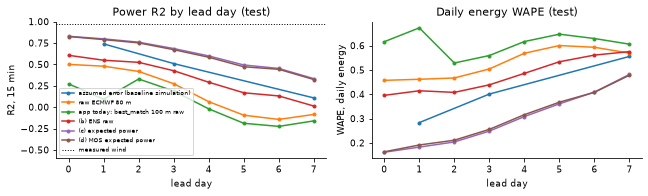

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
pr = POWER_RES.copy()
for name in ["assumed error (baseline simulation)", "raw ECMWF 80 m", "app today: best_match 100 m raw", "(b) ENS raw",
             "(c) expected power", "(d) MOS expected power"]:
    s = pr[(pr["scenario"] == name) & pr["d"].isin(LEADS)].sort_values("d")
    ax[0].plot(s["d"].astype(int), s["R2 15 min"], marker="o", ms=3, label=name)
    ax[1].plot(s["d"].astype(int), s["WAPE day"], marker="o", ms=3, label=name)
ax[0].axhline(r2(Y, MEAS), color="black", ls=":", lw=1, label="measured wind")
ax[0].set(xlabel="lead day", ylabel="R2, 15 min", title="Power R2 by lead day (test)", ylim=(-0.6, 1))
ax[1].set(xlabel="lead day", ylabel="WAPE, daily energy", title="Daily energy WAPE (test)")
ax[0].legend(fontsize=6)
fig.tight_layout()
fig.savefig(OUT / "power_by_lead.png", dpi=72)
plt.show()

## 6. Horizons: nowcasting from recent measured power against the forecast

**Nowcasting needs live SCADA** (the last hours of power and wind of every turbine). The application's database does
not receive SCADA yet, so everything in this section is what it *would* bring once that feed exists.

- **Nowcast model.** `kelmarsh_energy/` compared LSTM, LSTM + attention, Mamba2, XGBoost and a linear model on 10-minute
  energy, 10 steps ahead (R2 0.79 / 0.79 / 0.79 / 0.78 / 0.79 against 0.68 for persistence): the deep models gained
  nothing over boosted trees. XGBoost is not installed in `ml_def`, so the same idea runs here as CatBoost (ML2
  parameters, at most 600 trees), one model per horizon, every turbine pooled.
- **Inputs at issue time t** (a full hour): the last 8 quarters of the turbine's power (stops included, as SCADA shows
  it), its hourly means 3 to 6 h back, the last quarters of its nacelle wind, the park's mean power in the last quarter
  and the last hour, and the solar hour and day of year of the target quarter. **Target:** `cf15` of the quarter that
  starts (h - 1) x 15 min after t; h = 1 ... 96 (15 min to 24 h).
- **Periods.** Nowcast fitted on 2022-01 to 2024-02 (early stopping on Dec 2023 - Feb 2024). Blend weights fitted on
  2024-03-13 to 2024-08-31, where the forecast side is out of fold ((c) refitted without the month, section 4). Test: Sep-Dec 2024, as before.
- **The forecast side:** (c) expected power (section 5). Its lead time at a short horizon is between two bounds that
  the archive gives exactly:
  - **day 0** (latest run, lead 0-6 h): optimistic, as if a run were usable the moment it starts;
  - **day 1** (lead 24-30 h): pessimistic for the first hours.

  In the application a run is usable about 4-8 h after its start and the job refreshes every 12 h, so the real lead at
  horizon h is about h + 5 to h + 20 h: between the two bounds.
- **Blend:** w_h x nowcast + (1 - w_h) x forecast, one weight per horizon and bound, least squares on the blend months.

In [28]:
NOW_START, NOW_ES, NOW_FIT_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2023-12-01"), pd.Timestamp("2024-03-01")
HORIZONS = [1, 2, 4, 8, 12, 16, 24, 32, 48, 64, 96]
TURBS = sorted(QT["turbine"].unique())
full = pd.date_range(NOW_START - pd.Timedelta(hours=7), TEST_END - pd.Timedelta(minutes=15), freq="15min")
sub = QT[QT["qs"] >= full[0]]
CFA, CF15, WS15 = (sub.pivot(index="qs", columns="turbine", values=c).reindex(index=full, columns=TURBS).to_numpy()
                   for c in ["cf_all", "cf15", "ws15"])
PARK = np.nanmean(CFA, axis=1)


def lagmean(A, i, j0, j1):
    """Mean of A over quarters t - 15 j for j = j0..j1 (issue index i)."""
    return np.nanmean(np.stack([A[i - j] for j in range(j0, j1 + 1)]), axis=0)


def now_rows(issue_times, h):
    i = full.get_indexer(issue_times)
    i = i[(i >= 28) & (i + h - 1 < len(full))]
    X = {f"lag{j}": CFA[i - j] for j in range(1, 9)}
    for m, (a, b) in enumerate([(9, 12), (13, 16), (17, 20), (21, 24)], start=3):
        X[f"hour_m{m}"] = lagmean(CFA, i, a, b)
    X["ws_lag1"], X["ws_lag2"], X["ws_lag4"] = WS15[i - 1], WS15[i - 2], WS15[i - 4]
    X["ws_hour_m2"] = lagmean(WS15, i, 5, 8)
    n_t = len(TURBS)
    cols = {k: v.ravel() for k, v in X.items()}
    cols["park_lag1"] = np.repeat(PARK[i - 1], n_t)
    cols["park_hour"] = np.repeat(np.nanmean(np.stack([PARK[i - j] for j in range(1, 5)]), axis=0), n_t)
    tq = full[i + h - 1]
    tf = time_features(pd.Series(tq), np.asarray(tq.minute // 15))
    for c in ["hod_sin", "hod_cos", "doy_sin", "doy_cos"]:
        cols[c] = np.repeat(tf[c], n_t)
    df = pd.DataFrame(cols)
    df["issue"] = np.repeat(full[i], n_t)
    df["target_qs"] = np.repeat(tq, n_t)
    df["turbine"] = np.tile(TURBS, len(i))
    df["y"] = CF15[i + h - 1].ravel()
    return df[df["y"].notna()].reset_index(drop=True)


NOW_FEATS = [f"lag{j}" for j in range(1, 9)] + [f"hour_m{m}" for m in range(3, 7)] + [
    "ws_lag1", "ws_lag2", "ws_lag4", "ws_hour_m2", "park_lag1", "park_hour", "hod_sin", "hod_cos", "doy_sin", "doy_cos"]
issues_fit = pd.date_range(NOW_START, NOW_FIT_END - pd.Timedelta(hours=1), freq="h")
issues_val = pd.date_range(FC_START, TRAIN_END - pd.Timedelta(hours=1), freq="h")
issues_te = pd.date_range(TRAIN_END, TEST_END - pd.Timedelta(hours=1), freq="h")

# forecast-side power on the 15-minute grid: test from the final (c), blend months from the out-of-fold (c)
def nwp_grid(qcal_by_col, d, times, qs):
    vals = [power_cf(quarters_from_hourly(pd.Series(qcal_by_col[c], index=times).dropna(), qs)) for c in QCOLS]
    return pd.Series(np.mean(vals, axis=0), index=qs.to_numpy())


QG_TR = pd.Series(pd.date_range(FC_START, TRAIN_END - pd.Timedelta(minutes=15), freq="15min"))
NWP = {}
for d in (0, 1):
    sel_tr = (TR_ALL["d"] == d).to_numpy()
    s_tr = nwp_grid({c: OOF_C.loc[sel_tr, c].to_numpy() for c in QCOLS}, d, TR_ALL.loc[sel_tr, "time"].to_numpy(), QG_TR)
    sel = (M["d"] == d).to_numpy()
    s_te = nwp_grid({c: Q_C.loc[sel, c].to_numpy() for c in QCOLS}, d, M.loc[sel, "time"].to_numpy(), QG["qs"])
    NWP[d] = pd.concat([s_tr, s_te])
    NWP[d] = NWP[d][~NWP[d].index.duplicated(keep="last")]

h =   1: 379 trees, 1 s


h =   2: 230 trees, 2 s


h =   4: 175 trees, 3 s


h =   8: 192 trees, 3 s


h =  12: 152 trees, 4 s


h =  16: 126 trees, 5 s


... (6 outputs left out)

                       rows  persistence  nowcast  forecast, day 0 bound  forecast, day 1 bound  blend, day 0 bound  blend, day 1 bound
h (quarters) horizon                                                                                                                   
1            0.25 h   16946        0.944    0.948                  0.830                  0.798               0.949               0.948
2            0.5 h    16940        0.900    0.908                  0.828                  0.798               0.911               0.909
4            1 h      16961        0.840    0.857                  0.830                  0.800               0.875               0.868
8            2 h      16953        0.750    0.780                  0.830                  0.800               0.846               0.827
12           3 h      16940        0.669    0.710                  0.830                  0.800               0.837               0.812
16           4 h      16928        0.594    0.64

blend weight of the nowcast, fitted on the blend months:


h        1     2     4     8     12    16    24    32    48    64    96
bound                                                                  
day 0  0.85  0.70  0.49  0.24  0.14  0.08  0.05  0.03  0.03  0.02  0.02
day 1  0.88  0.76  0.59  0.32  0.18  0.11  0.06  0.04  0.02  0.02  0.02

first horizon where the blend adds less than 0.01 R2 over the forecast alone: {'day 0': '3 h', 'day 1': '4 h'}


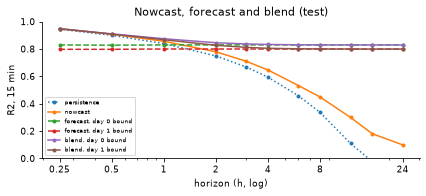

In [29]:
t0 = time.time()
NOWCAST, rows, WEIGHTS = {}, [], []
for h in HORIZONS:
    tr = now_rows(issues_fit, h)
    tr = tr[tr["target_qs"] < NOW_FIT_END]
    fit, es = tr[tr["target_qs"] < NOW_ES], tr[tr["issue"] >= NOW_ES]
    m = CatBoostRegressor(**PCB, iterations=600)
    m.fit(fit[NOW_FEATS], fit["y"], eval_set=(es[NOW_FEATS], es["y"]), early_stopping_rounds=50)
    NOWCAST[h] = m
    out = {}
    for name, iss, last in [("val", issues_val, TRAIN_END), ("test", issues_te, TEST_END)]:
        df = now_rows(iss, h)
        df = df[df["target_qs"] < last].copy()
        df["now"] = np.clip(m.predict(df[NOW_FEATS]), 0, 1)
        df["persist"] = df["lag1"]
        for d in (0, 1):
            df[f"nwp{d}"] = NWP[d].reindex(df["target_qs"]).to_numpy()
        out[name] = df.dropna(subset=["now", "nwp0", "nwp1", "persist"])
    for d in (0, 1):
        v = out["val"]
        a, b, y = v["now"].to_numpy(), v[f"nwp{d}"].to_numpy(), v["y"].to_numpy()
        w = float(np.clip(np.sum((y - b) * (a - b)) / np.sum((a - b) ** 2), 0, 1))
        WEIGHTS.append({"h": h, "bound": f"day {d}", "w_nowcast": w})
        out["test"][f"blend{d}"] = w * out["test"]["now"] + (1 - w) * out["test"][f"nwp{d}"]
    te_ = out["test"]
    y = te_["y"].to_numpy()
    rows.append({"h (quarters)": h, "horizon": f"{h * 15 / 60:g} h", "rows": len(te_),
                 **{k: r2(y, te_[c].to_numpy()) for k, c in [
                     ("persistence", "persist"), ("nowcast", "now"), ("forecast, day 0 bound", "nwp0"),
                     ("forecast, day 1 bound", "nwp1"), ("blend, day 0 bound", "blend0"), ("blend, day 1 bound", "blend1")]}})
    print(f"h = {h:3d}: {m.tree_count_} trees, {time.time() - t0:.0f} s", flush=True)
NOW_RES = pd.DataFrame(rows).set_index(["h (quarters)", "horizon"])
WTS = pd.DataFrame(WEIGHTS).pivot(index="h", columns="bound", values="w_nowcast")
print("TEST, R2 per quarter by horizon (time from the issue to the end of the target quarter):")
display(NOW_RES.round(3))
print("blend weight of the nowcast, fitted on the blend months:")
display(WTS.round(2).T)
NOW_RES.to_csv(OUT / "nowcast_by_horizon_test.csv")


def crossover(bound, tol=0.01):
    gain = NOW_RES[f"blend, {bound} bound"] - NOW_RES[f"forecast, {bound} bound"]
    later = gain[gain < tol]
    return later.index[0][1] if len(later) else "beyond 24 h"


CROSS = {b: crossover(b) for b in ["day 0", "day 1"]}
print("first horizon where the blend adds less than 0.01 R2 over the forecast alone:", CROSS)

fig, ax = plt.subplots(figsize=(6, 2.8))
x = [h * 15 / 60 for h in HORIZONS]
for c, st in [("persistence", ":"), ("nowcast", "-"), ("forecast, day 0 bound", "--"), ("forecast, day 1 bound", "--"),
              ("blend, day 0 bound", "-"), ("blend, day 1 bound", "-")]:
    ax.plot(x, NOW_RES[c].to_numpy(), st, marker="o", ms=3, label=c)
ax.set(xscale="log", xlabel="horizon (h, log)", ylabel="R2, 15 min", title="Nowcast, forecast and blend (test)",
       ylim=(0, 1))
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8, 24])
ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8", "24"])
ax.legend(fontsize=6)
fig.tight_layout()
fig.savefig(OUT / "nowcast_by_horizon.png", dpi=72)
plt.show()

## 7. The new ML2 reference with real forecast error

Same format as section 0 of `care_ml2_power_15min.md`: R2 per quarter hour, every clean quarter of the six Kelmarsh
turbines in the test months (Sep-Dec 2024). WAPE: daily energy per turbine for a lead day, weekly energy per turbine
for the measured wind and the whole week.

In [30]:
REF_COLS = {
    "assumed error (baseline simulation)": "assumed error, baseline method",
    "app today: best_match 100 m raw": "app today (best_match 100 m, raw)",
    "raw ECMWF 80 m": "raw ECMWF 80 m",
    "(b) ENS raw": "mean of 7 models, raw",
    "(c) weights per lead day": "(c) weights, point",
    "(c) expected power": "(c) weights, expected power",
    "(d) MOS expected power": "(d) CatBoost MOS, expected power",
}
ref_rows = []
for d, label in [("measured", "measured wind (no forecast error)"), (1, "day 1"), (3, "day 3"), (7, "day 7"),
                 ("week", "whole week (day k uses lead day k)")]:
    r2_row, w_row = {"lead time": label}, {"lead time": label}
    for sc, col in REF_COLS.items():
        s = POWER_RES[(POWER_RES["scenario"] == ("measured wind" if d == "measured" else sc)) & (POWER_RES["d"] == d)]
        if len(s):
            r2_row[col] = s["R2 15 min"].iloc[0]
            w_row[col] = s["WAPE week" if d in ("week", "measured") else "WAPE day"].iloc[0]
    ref_rows.append((r2_row, w_row))
REF_R2 = pd.DataFrame([a for a, _ in ref_rows]).set_index("lead time")
REF_WAPE = pd.DataFrame([b for _, b in ref_rows]).set_index("lead time")
print("R2 per quarter hour, Kelmarsh test months:")
display(REF_R2.round(3))
print("WAPE of the energy (daily for a lead day, weekly for measured and whole week):")
display(REF_WAPE.round(3))
REF_R2.to_csv(OUT / "ml2_reference_r2.csv")
REF_WAPE.to_csv(OUT / "ml2_reference_wape.csv")

R2 per quarter hour, Kelmarsh test months:


                                    assumed error, baseline method  app today (best_match 100 m, raw)  raw ECMWF 80 m  mean of 7 models, raw  (c) weights, point  (c) weights, expected power  \
lead time                                                                                                                                                                                       
measured wind (no forecast error)                            0.972                              0.972           0.972                  0.972               0.972                        0.972   
day 1                                                        0.740                              0.092           0.479                  0.549               0.795                        0.799   
day 3                                                        0.510                              0.189           0.274                  0.426               0.676                        0.685   
day 7                              

WAPE of the energy (daily for a lead day, weekly for measured and whole week):


                                    assumed error, baseline method  app today (best_match 100 m, raw)  raw ECMWF 80 m  mean of 7 models, raw  (c) weights, point  (c) weights, expected power  \
lead time                                                                                                                                                                                       
measured wind (no forecast error)                            0.019                              0.019           0.019                  0.019               0.019                        0.019   
day 1                                                        0.284                              0.673           0.462                  0.414               0.185                        0.183   
day 3                                                        0.401                              0.559           0.504                  0.439               0.252                        0.249   
day 7                              

## 8. Saved model and contract

The corrected forecast beats the raw one at every lead day (sections 4.2 and 5.2). The model kept is **(c), weights per
lead day with its 9 residual quantiles**. The CatBoost MOS does not beat it: same wind RMSE (4.2), slightly lower power
R2 over the week (-0.015 [-0.025, -0.007], 5.2) and the same interval quality (pinball 0.253-0.686 against
0.257-0.685, 4.3). It would add a 470 KB file and a dependency for nothing measured. (c) is a few numbers per lead
day, so the model and its contract are one JSON file.

**It is the Kelmarsh correction**: the weights, intercepts and quantiles describe the error of these models against the
nacelle anemometers of six Senvion MM92 at 68.5-78.5 m. For another park it is a template: the same inputs, refitted
on that park's measured wind.

In [31]:
def r(x, n=3):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), n)


def wind_rmse(name):
    return {str(d): r(WIND_TEST[(WIND_TEST["method"] == name) & (WIND_TEST["d"] == d)]["RMSE"].iloc[0], 2) for d in LEADS}


def power_metric(name, stat):
    return {str(d): r(POWER_RES[(POWER_RES["scenario"] == name) & (POWER_RES["d"] == d)][stat].iloc[0])
            for d in LEADS + ["week"]}


contract = {
    "name": "ML2 wind correction for Kelmarsh: weights per lead day with residual quantiles (method (c))",
    "created": "2026-11-08",
    "notebook": "notebooks/ml2_weather_correction.ipynb",
    "results": "notebooks/ml2_weather_correction.md",
    "scope": "Kelmarsh only (52.40 N, -0.94 E; 6 x Senvion MM92, hub 68.5-78.5 m). The numbers encode this park's error "
             "against its nacelle anemometers; do not apply them to another park. The method transfers; the numbers do not.",
    "target": {"name": "ws_obs", "unit": "m/s",
               "definition": "park mean of the nacelle wind speed of the turbines in operation: mean of the 10-minute "
                             "rows from H - 30 min to H + 30 min, compared with the forecast valid at the full hour H (UTC)"},
    "inputs": {
        "api": "Open-Meteo; trained on the Previous Runs API (previous-runs-api.open-meteo.com), served from the Forecast "
               "API with the same `models`. Lead day d = whole days between the run and the valid hour (0..7).",
        "request": {"latitude": 52.4013, "longitude": -0.9435, "wind_speed_unit": "ms", "timezone": "GMT",
                    "cell_selection": "land"},
        "models": {LABEL[m]: {"open_meteo_model": m, "variable": f"wind_speed_{OM_MODELS[m][1]}"} for m in ENSEMBLE},
        "missing": "ICON has no day 7 and ICON-EU no day 5-7; a missing model is replaced by ens_mean, the mean of the "
                   "models available for that hour",
    },
    "formula": {
        "point": "ws_corr = intercept_d + sum_m weight_dm * ws_m",
        "quantiles": "q_j = ws_corr + residual_quantile_dj, alpha_j = 0.1, 0.2, ..., 0.9; clip at 0",
        "power": "feed each of the 9 quantile series through the ML2 wind-to-power model (serving recipe of "
                 "feature_contract_15min.json) and average the 9 powers (expected power); P10 / P90 power from q10 / q90",
    },
    "per_lead_day": {
        str(d): {"intercept": r(SIMPLE[("w", d)][0]),
                 "weights": {c: r(w) for c, w in zip(SIMPLE[("w", d)][2], SIMPLE[("w", d)][1])},
                 "residual_quantiles": [r(x) for x in SIMPLE[("w_qs", d)]]}
        for d in LEADS},
    "training": {"train": f"{FC_START.date()} to {(TRAIN_END - pd.Timedelta(days=1)).date()}",
                 "test": f"{TRAIN_END.date()} to {(TEST_END - pd.Timedelta(days=1)).date()}"},
    "test": {
        "wind_rmse_m_s": {"raw ECMWF 80 m": wind_rmse("(a) raw ECMWF"), "best_match 100 m (app today)":
                          wind_rmse("best_match 100m raw"), "this model": wind_rmse("(c) weights per lead day")},
        "wind_p10_p90_coverage": {str(d): r(COV[(COV["method"] == "(c) residual quantiles") & (COV["d"] == d)]
                                            ["coverage"].iloc[0]) for d in LEADS},
        "power_r2_15min": {"app today": power_metric("app today: best_match 100 m raw", "R2 15 min"),
                           "this model, expected power": power_metric("(c) expected power", "R2 15 min")},
        "power_wape_daily_energy": {"app today": power_metric("app today: best_match 100 m raw", "WAPE day"),
                                    "this model, expected power": power_metric("(c) expected power", "WAPE day")},
    },
    "limits": [
        "10 months of archived forecasts (2024-03 to 2024-12); season cannot be learned and is not an input",
        "fitted on spring-summer, tested on autumn-winter: the corrected daily energy is 5-15% low on test (weekly "
        "-10%); refit monthly",
        "the Open-Meteo lead-day archive starts in 2024, so the history cannot be extended backwards",
    ],
}
CONTRACT_FILE = MODELS_DIR / "wind_correction_kelmarsh.json"
CONTRACT_FILE.write_text(json.dumps(contract, indent=2) + "\n")
print(f"{CONTRACT_FILE.name}: {CONTRACT_FILE.stat().st_size / 1024:.1f} KB")

wind_correction_kelmarsh.json: 7.6 KB


## 9. In short

- **Real error against assumed.** Raw Open-Meteo at the hub is biased +0.9 to +1.7 m/s against the nacelle wind; once
  the bias is removed its spread (SD 1.3 / 1.8 / 2.9 m/s for ECMWF at day 1 / 3 / 7) is a little *smaller* than assumed
  (1.5 / 2.2 / 3.3), and less persistent from hour to hour (r 0.81-0.93 against 0.95).
- **What the correction gains** (wind RMSE on test, day 1 / 3 / 7): raw ECMWF 1.88 / 2.25 / 2.99 m/s, mean of models
  1.81 / 2.09 / 2.65, bias removed 1.28 / 1.64 / 2.34, **weights per lead day 0.99 / 1.40 / 2.27**. The CatBoost MOS
  ties the weights; the bias carries most of the gain, the weights the rest.
- **New ML2 reference** (Kelmarsh, R2 per quarter, whole week): app today 0.09, raw ECMWF 0.20, **corrected 0.59**,
  against 0.46 for the assumed error. Weekly energy WAPE 0.48 / 0.41 / **0.20** / 0.25.
- **Horizons.** Nowcasting from live SCADA wins below about 1 h and adds to the forecast up to 3-4 h; beyond that the
  corrected forecast alone is as good. The application has no live SCADA yet.
- Details, tables and the application design: `notebooks/ml2_weather_correction.md`.